# 16 · Kümeleme - Bölümleme Yöntemleri (Clustering: Partitioning Methods)

> **Bu notebook'ta ne öğreneceğiz?**
> 01-15 arası notebook'ların hepsi **denetimli öğrenme** (supervised learning) üzerineydi:
> elimizde her örnek için bir hedef etiket ($y$) vardı ve modelin görevi $X \to y$
> eşlemesini öğrenmekti. Bu notebook'la birlikte **denetimsiz öğrenme**ye (unsupervised
> learning) geçiyoruz: artık hedef etiket **yok**, elimizde sadece öznitelikler ($X$) var ve
> amacımız verinin kendi içindeki yapıyı (doğal gruplanmaları) keşfetmek. İlk durağımız
> **bölümleme (partitioning) tabanlı kümeleme**: **K-Means**'i (Lloyd algoritması +
> k-means++ başlatma) sıfırdan kodlayacağız, aykırı değerlere karşı daha dayanıklı
> **K-Medoids (PAM)**'ı sıfırdan implemente edeceğiz, ve büyük ölçekli veri için
> **Mini-Batch K-Means**'in hız/kalite dengesini inceleyeceğiz. Küme sayısını ($k$) seçmek
> için Elbow Method ve Silhouette Score'u da uygulamalı olarak öğreneceğiz. Bir sonraki
> notebook (17 · Hiyerarşik ve Yoğunluk Tabanlı Kümeleme), K-Means'in burada göreceğimiz
> sınırlamalarını (küresel küme varsayımı, $k$'nın önceden bilinmesi gerekliliği) çözen
> yöntemlere (Agglomerative, DBSCAN, GMM) odaklanacak.
>
> **Önkoşul:** 01 · Veri Ön İşleme (ölçekleme), 11 · Model Değerlendirme Metrikleri
> (metrik okuryazarlığı — burada yeni bir metrik ailesi, kümeleme metrikleri, göreceğiz).
>
> **Veri:** Mall Customer Segmentation (Kaggle, 200 müşteri, gelir+harcama skoru — temiz ve
> görsel olarak ayrışan kümeler), Wholesale Customers (UCI, 440 toptan satış müşterisi,
> ağır çarpık/aykırı-değerli harcama kategorileri — K-Medoids'in gerekçesini gösterecek),
> ve ölçeklenebilirlik testi için sentetik büyük veri (`make_blobs`).
>
> **Araçlar:** `sklearn.cluster` (`KMeans`, `MiniBatchKMeans`), `sklearn.metrics`
> (`silhouette_score`), `sklearn_extra.cluster.KMedoids`, R (`stats::kmeans`,
> `cluster::pam`), DuckDB (SQL).

## 1 · Denetimsiz Öğrenme ve Kümeleme Problemi

**Denetimli vs denetimsiz:** Denetimli öğrenmede veri $\{(x_i, y_i)\}_{i=1}^n$ şeklindedir
ve amaç $f: X \to y$'yi öğrenmektir (hata, gerçek $y$ ile karşılaştırılarak ölçülür).
Denetimsiz öğrenmede veri sadece $\{x_i\}_{i=1}^n$'dir — "doğru cevap" yoktur, dolayısıyla
başarı ölçütleri de farklıdır (dışsal bir etiketle karşılaştırma yerine, kümelerin
kendi-içi tutarlılığına bakarız — bkz. §4, Silhouette Score).

**Kümeleme (clustering):** $n$ örneği, aynı kümedeki örnekler birbirine **benzer**, farklı
kümedeki örnekler birbirinden **farklı** olacak şekilde $k$ gruba ayırma problemi. Üç ana
aile vardır:

| Aile | Fikir | Bu seride |
|---|---|---|
| **Bölümleme (partitioning)** | Veriyi $k$ adet ayrık kümeye böl, her nokta tam olarak bir kümeye ait | **Bu notebook** (K-Means, K-Medoids, Mini-Batch K-Means) |
| **Hiyerarşik (hierarchical)** | İç içe geçmiş küme ağacı (dendrogram) kur, $k$'yı sonradan seç | 17 · Hiyerarşik ve Yoğunluk Tabanlı Kümeleme |
| **Yoğunluk tabanlı (density-based)** | Yüksek yoğunluklu bölgeleri küme say, gürültüyü ayrı sınıfla | 17 · (DBSCAN) |
| **Dağılım tabanlı (distribution-based)** | Her kümeyi bir olasılık dağılımı (örn. Gauss) olarak modelle | 17 · (Gaussian Mixture Model) |

**Endüstride nerede kullanılır?**
1. **Perakende/Pazarlama — müşteri segmentasyonu:** Gelir, harcama alışkanlığı, sıklık gibi
   özniteliklere göre müşterileri gruplayıp her segmente özel kampanya tasarlamak (bu
   notebook'ta Mall Customer verisiyle bizzat yapacağımız şey).
2. **Tedarik zinciri — toptan satış müşteri profilleme:** Bir dağıtıcının müşterilerini
   (restoran/otel vs. perakende, hangi ürün kategorisinde ne kadar harcadıklarına göre)
   gruplayıp lojistik/stok kararlarını segmente göre optimize etmek (Wholesale Customers
   verisiyle yapacağımız şey).
3. **Görüntü işleme — renk nicemleme (color quantization):** Bir görüntüdeki milyonlarca
   pikseli $k$ renk kümesine indirgeyip dosya boyutunu küçültmek (K-Means'in klasik bir
   uygulaması — GIF paleti oluşturma).
4. **Biyoinformatik — gen ifadesi kümeleme:** Benzer ifade örüntüsü gösteren genleri
   gruplayıp ortak biyolojik yol (pathway) hipotezleri üretmek.
5. **Anomali/dolandırıcılık ön-taraması:** Normal davranış kümelerinin **dışında** kalan
   noktaları (küçük/uzak kümeler veya hiçbir kümeye net ait olmayan noktalar) şüpheli
   olarak işaretlemek (18 · Anomaly Detection'da bunu daha resmi yöntemlerle göreceğiz).

## 2 · K-Means: Amaç Fonksiyonu ve Lloyd Algoritması

**Amaç fonksiyonu (WCSS — Within-Cluster Sum of Squares):** $k$ küme merkezi (centroid)
$\mu_1, \dots, \mu_k \in \mathbb{R}^d$ ve bir atama $c: \{1,\dots,n\} \to \{1,\dots,k\}$
için K-Means şu miktarı minimize etmeye çalışır:

$$J(\{\mu_j\}, c) = \sum_{i=1}^{n} \left\lVert x_i - \mu_{c(i)} \right\rVert^2
= \sum_{j=1}^{k} \sum_{i: c(i)=j} \left\lVert x_i - \mu_j \right\rVert^2$$

Bu, **NP-zor** bir kombinatorik optimizasyon problemidir (tüm olası atamaları denemek
$k^n$ işlem gerektirir). **Lloyd algoritması** (1957, pratikte "K-Means algoritması" ile eş
anlamlı kullanılır) yerel bir optimuma **yakınsayan** iteratif bir sezgisel yöntemdir:

1. **Başlatma:** $k$ merkez rastgele seçilir (bkz. §3 — random vs k-means++).
2. **Atama adımı (E-step benzeri):** Her $x_i$, en yakın merkeze atanır:
   $c(i) \leftarrow \arg\min_j \lVert x_i - \mu_j \rVert^2$
3. **Güncelleme adımı (M-step benzeri):** Her merkez, kendisine atanan noktaların
   ortalaması olarak yeniden hesaplanır: $\mu_j \leftarrow \frac{1}{|C_j|}\sum_{i \in C_j} x_i$
4. Atamalar değişmeyene kadar (veya maksimum iterasyona ulaşana kadar) 2-3 tekrarlanır.

**Yakınsama garantisi:** Her iterasyonda $J$ **monoton azalır** (atama adımı her noktayı
kendisine en yakın merkeze taşıyarak $J$'yi azaltır ya da sabit tutar; güncelleme adımı,
küme-içi kareler toplamını minimize eden noktanın tam olarak ortalama olduğu gerçeğinden
dolayı $J$'yi azaltır ya da sabit tutar). $J \geq 0$ ve azalan olduğu için algoritma sonlu
adımda **bir** yerel optimuma yakınsar — ama **global** optimuma değil (farklı
başlatmalar farklı yerel optimumlara götürebilir, bu yüzden pratikte `n_init` kez
tekrarlanır ve en düşük $J$ olan çözüm tutulur).

**Hesaplama karmaşıklığı:** Her iterasyon $O(n \cdot k \cdot d)$ (her noktanın her merkeze
uzaklığı hesaplanır), $I$ iterasyonla toplam $O(n \cdot k \cdot d \cdot I)$ — $n$'de
**doğrusal**, bu da K-Means'i büyük veri kümeleri için pratik kılan temel özelliktir
(hiyerarşik kümelemenin $O(n^2 \log n)$'ine kıyasla).

**Endüstride nerede kullanılır?** Görüntü sıkıştırmada (renk paleti azaltma) ve arama
motoru altyapısında (vektör niceleme / "vector quantization" — yüksek boyutlu embedding
vektörlerini yaklaşık en-yakın-komşu aramasını hızlandırmak için önceden kümelere ayırma,
örn. Faiss/IVF indeksleri) K-Means'in doğrusal ölçeklenebilirliği doğrudan devreye girer.

## 3 · Başlatma Stratejisi: Rastgele vs k-means++

Lloyd algoritmasının en büyük zayıflığı **başlatmaya duyarlılığı**dır: kötü seçilmiş
başlangıç merkezleri, kötü bir yerel optimuma (yüksek $J$) yakınsayabilir, hatta bazı
kümelerin "boş kalmasına" (hiç nokta atanmamasına) yol açabilir.

**Rastgele başlatma:** $k$ merkez, veri noktaları arasından **düzgün rastgele** (uniform
random) seçilir. Basit ama şanssız çıkabilir (örn. iki merkez aynı gerçek kümeye düşebilir).

**k-means++ (Arthur & Vassilvitskii, 2007):** Merkezleri **birbirinden uzak** olacak
şekilde olasılıksal olarak seçer:
1. İlk merkez $\mu_1$, veri noktaları arasından düzgün rastgele seçilir.
2. Her sonraki merkez için, her $x_i$ noktası şu olasılıkla seçilir (zaten seçilmiş
   merkezlere göre en yakın uzaklığın karesiyle **orantılı**):

$$P(x_i \text{ seçilir}) = \frac{D(x_i)^2}{\sum_{i'=1}^{n} D(x_{i'})^2}, \quad
D(x_i) = \min_{j \text{ (seçilmiş)}} \lVert x_i - \mu_j \rVert$$

3. $k$ merkez seçilene kadar 2 tekrarlanır, sonra normal Lloyd iterasyonlarına geçilir.

**Neden işe yarar?** Zaten uzak olan noktaların seçilme olasılığı yüksek olduğu için,
merkezler doğal olarak birbirinden **yayılmış** çıkar — bu hem daha iyi bir başlangıç
$J$ değeri hem de daha az `n_init` tekrarıyla iyi bir sonuca ulaşma anlamına gelir. Arthur &
Vassilvitskii, k-means++'ın beklenen $J$ değerinin optimal $J^*$'den en fazla
$O(\log k)$ kat uzakta olduğunu **kanıtlamıştır** — rastgele başlatmanın böyle bir garantisi
yoktur. `sklearn.cluster.KMeans`'te `init='k-means++'` **varsayılan** değerdir.

## 4 · Küme Sayısını ($k$) Seçmek: Elbow Method ve Silhouette Score

K-Means'in en büyük pratik zorluğu, $k$'nın **önceden** verilmesi gerekmesidir. İki
yaygın yöntem:

**Elbow Method (Dirsek Yöntemi):** Farklı $k$ değerleri için WCSS ($J$) hesaplanır ve
$k$'ya karşı çizilir. $J$, $k$ arttıkça monoton azalır (limit durumda $k=n$'de $J=0$), ama
azalma hızı **gerçek küme sayısına** ulaşıldıktan sonra belirgin şekilde yavaşlar —
grafikte bir "dirsek" (elbow) oluşur. Dirsek noktası, ek kümelerin artık anlamlı bir
kazanç sağlamadığı $k$'yı işaret eder. Dezavantajı: dirsek her zaman net görünmez, öznel
bir okuma gerektirir.

**Silhouette Score (Rousseeuw, 1987):** Her nokta $i$ için:

$$a(i) = \text{aynı kümedeki diğer noktalara ortalama uzaklık (küme-içi uyum)}$$
$$b(i) = \min_{j \neq c(i)} \left(\text{$j$ kümesindeki noktalara ortalama uzaklık}\right)
\text{ (en yakın komşu kümeye ayrışma)}$$
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))} \in [-1, 1]$$

$s(i) \approx 1$: nokta kendi kümesine çok uygun, komşu kümeden uzak (iyi kümeleme).
$s(i) \approx 0$: nokta iki küme arasında sınırda. $s(i) < 0$: nokta muhtemelen **yanlış**
kümeye atanmış. **Ortalama silhouette skoru** $\bar{s} = \frac{1}{n}\sum_i s(i)$, tüm
kümelemenin genel kalitesini tek sayıya indirger — en yüksek $\bar{s}$'yi veren $k$ seçilir.
Elbow'dan farkı: dışsal bir etiket gerektirmez (tamamen denetimsizdir) ve **tek bir sayı**
üretir, bu da $k$ seçimini otomatikleştirmeyi kolaylaştırır — ama $O(n^2)$ karmaşıklığı
büyük veride maliyetlidir (örnekleme ile yaklaşıklanabilir).

**Endüstride nerede kullanılır?** A/B test/deney tasarımı öncesi kaç davranışsal kullanıcı
segmenti tanımlanacağına karar verirken (çok az segment = kaba, çok fazla segment =
istatistiksel güç kaybı ve operasyonel karmaşıklık) silhouette/elbow analizi standart bir
ön-adımdır.

## 5 · K-Medoids (PAM): K-Means Ne Zaman Yetersiz Kalır?

K-Means'in üç önemli varsayımı/zayıflığı vardır:

1. **Aykırı değerlere aşırı duyarlılık:** Merkez, kümedeki noktaların **ortalamasıdır** —
   ortalama, aykırı değerlerden güçlü şekilde etkilenir (tek bir çok-uzak nokta merkezi
   önemli ölçüde kaydırabilir).
2. **Sadece Öklid uzaklığı (karesel):** Amaç fonksiyonu $\lVert x_i - \mu_j \rVert^2$
   olduğu için doğası gereği Öklid uzaklığına bağlıdır — kategorik veri veya özel bir
   uzaklık metriği (örn. Manhattan, kosinüs, düzenleme uzaklığı) kullanmak istendiğinde
   K-Means doğrudan uygulanamaz.
3. **Merkez, gerçek bir veri noktası olmayabilir:** Ortalama alma, yorumlanabilirliği
   zayıflatabilir (örn. "ortalama müşteri" gerçekte var olmayan, kesirli/anlamsız
   değerlere sahip hayali bir profil olabilir).

**K-Medoids (Kaufman & Rousseeuw, 1987/1990 — PAM: Partitioning Around Medoids)** bu
sorunları, merkez yerine **medoid** kullanarak çözer: medoid, o kümedeki **gerçek bir veri
noktasıdır** ve kümedeki diğer tüm noktalara olan **toplam uzaklığı minimize eden**
noktadır:

$$\text{medoid}_j = \arg\min_{x_m \in C_j} \sum_{x_i \in C_j} d(x_i, x_m)$$

**PAM Algoritması** iki fazdan oluşur:

- **BUILD fazı:** İlk $k$ medoid, açgözlü (greedy) şekilde seçilir — her adımda, toplam
  uzaklığı en çok azaltacak nokta medoid olarak eklenir.
- **SWAP fazı:** Her medoid $m$ ve her medoid-olmayan nokta $o$ çifti için, $m$'yi $o$ ile
  **değiştirmenin** toplam maliyeti ($\sum_i \min_j d(x_i, \text{medoid}_j)$) azaltıp
  azaltmadığı kontrol edilir; azaltıyorsa takas yapılır. İyileştirme kalmayana kadar
  tekrarlanır.

**Neden dayanıklı (robust)?** Medoid bir **veri noktası** olduğu için, tek bir aşırı aykırı
değer medoid konumunu K-Means'teki gibi "sürükleyemez" — medoid olabilmesi için o noktanın
kendisinin diğerlerine yakın olması gerekir, aykırı bir nokta bu kritere neredeyse hiç
uymaz. Ayrıca $d(\cdot,\cdot)$ **herhangi bir** uzaklık/benzemezlik ölçüsü olabilir (sadece
Öklid değil) — bu, K-Medoids'i karma/kategorik veri veya özel alan-bilgisi uzaklıkları için
K-Means'ten daha esnek kılar. Bedeli: SWAP fazının her adımı $O(k(n-k)^2)$ karmaşıklığında
olduğu için PAM, K-Means'ten **çok daha yavaştır** — büyük veri için pratik değildir
(CLARA/CLARANS gibi örnekleme-tabanlı varyantlar bunun için geliştirilmiştir).

**Endüstride nerede kullanılır?** Sigorta/finansta poliçe veya işlem kümelemesi, kategorik
ve sayısal özniteliklerin karıştığı (örn. Gower uzaklığıyla) müşteri profilleme
senaryolarında, ve tıbbi kayıt kümelemesinde (hasta profillerinin "gerçek bir hasta" ile
temsil edilmesi, ortalama alınarak var olmayan bir "hayalet hasta" üretilmemesi klinik
yorumlanabilirlik için tercih edilir) PAM/K-Medoids tercih edilir.

## 6 · Mini-Batch K-Means: Büyük Veride Ölçeklenebilirlik

Standart ("batch") K-Means'in her iterasyonu **tüm** veri kümesini tarar
($O(n \cdot k \cdot d)$). $n$ milyonlarca/milyarlarca olduğunda (web ölçeğinde tıklama
akışı, gerçek zamanlı sensör verisi) bu, her iterasyonu pahalı hale getirir.

**Mini-Batch K-Means (Sculley, 2010 — "Web-Scale K-Means Clustering", Google)** her
iterasyonda **tüm veri yerine küçük, rastgele bir alt-küme (mini-batch)** kullanır:

1. Rastgele bir mini-batch $B \subset \{x_1,\dots,x_n\}$ örneklenir ($|B| \ll n$,
   tipik olarak birkaç yüz-bin nokta).
2. Mini-batch'teki her nokta, en yakın merkeze atanır (standart atama adımı, ama sadece
   $B$ üzerinde).
3. Merkezler, **tam yeniden hesaplama yerine** her nokta için tek bir **öğrenme oranı
   azaltılmış (learning-rate-decayed) güncelleme** ile kaydırılır:
   $\mu_j \leftarrow \mu_j + \frac{1}{v_j}(x_i - \mu_j)$, burada $v_j$ o merkeze o ana
   kadar atanmış toplam nokta sayısıdır (sayaç arttıkça öğrenme oranı $1/v_j$ küçülür —
   merkez zamanla "sabitlenir", tıpkı çevrimiçi ortalama hesaplama gibi).
4. Yakınsayana (veya iterasyon bütçesi bitene) kadar 1-3 tekrarlanır.

**Kalite/hız dengesi:** Her iterasyon çok daha ucuzdur ($O(|B| \cdot k \cdot d)$, $n$'den
bağımsız), bu da toplam çalışma süresini büyük ölçüde kısaltır — bedelinde, mini-batch'in
gürültülü olması nedeniyle nihai WCSS'nin standart K-Means'e göre **biraz daha yüksek**
(daha kötü) çıkması beklenir. Pratikte bu fark genellikle küçüktür ve büyük veride hız
kazancı bu küçük kalite kaybına değer. `sklearn.cluster.MiniBatchKMeans`, `batch_size` ve
`n_init` parametreleriyle bu dengeyi ayarlamaya izin verir.

**Endüstride nerede kullanılır?** Sculley'nin orijinal makalesi doğrudan Google'ın web
ölçeğinde kullanıcı oturumu/sorgu kümelemesi motivasyonuyla yazılmıştır; günümüzde
gerçek-zamanlı öneri sistemlerinde (kullanıcı davranış akışını sürekli güncellenen
kümelere atama) ve akan (streaming) sensör/IoT verisinde online kümeleme için standart
bir araçtır.

## 7 · Özet Karşılaştırma ve Bir Sonraki Adım

| Yöntem | Merkez temsili | Uzaklık | Aykırı değere dayanıklılık | Ölçeklenebilirlik | Küme şekli varsayımı |
|---|---|---|---|---|---|
| **K-Means** | Ortalama (centroid, gerçek olmayabilir) | Sadece Öklid (kare) | Düşük | Yüksek ($O(nkd)$/iter.) | Küresel, benzer boyut/yoğunluk |
| **K-Medoids (PAM)** | Medoid (gerçek veri noktası) | Herhangi bir $d(\cdot,\cdot)$ | Yüksek | Düşük ($O(k(n-k)^2)$/iter.) | Küresel, benzer boyut/yoğunluk |
| **Mini-Batch K-Means** | Ortalama (centroid) | Sadece Öklid (kare) | Düşük | Çok yüksek (batch boyutuyla ayarlanabilir) | Küresel, benzer boyut/yoğunluk |

Üçü de **bölümleme tabanlı**dır ve ortak bir temel zayıflığı paylaşır: kümelerin **küresel
(convex) ve benzer boyut/yoğunlukta** olduğunu **varsayarlar** — çünkü hepsi "en yakın
merkeze ata" mantığına dayanır, bu da doğal olarak Voronoi-benzeri, dışbükey bölgeler
üretir. İç içe geçmiş halkalar, hilal şekilli kümeler, ya da çok farklı yoğunluklara sahip
kümeler karşısında üçü de başarısız olur. **17 · Hiyerarşik ve Yoğunluk Tabanlı
Kümeleme**'de göreceğimiz DBSCAN (yoğunluk tabanlı, keyfi şekil) ve Gaussian Mixture Model
(yumuşak/olasılıksal atama, eliptik kümeler) bu sınırlamaların bir kısmını çözer — Python
Uygulaması'nın sonunda (Adım 16) bunu sentetik "ay" şekilli bir veri kümesiyle somut olarak
göstereceğiz.

# 🐍 Python Uygulaması

Adımlar:
1. Mall Customer Segmentation verisinin yüklenmesi ve keşfi
2. K-Means'in sıfırdan implementasyonu (Lloyd algoritması, rastgele başlatma)
3. k-means++ başlatmasının sıfırdan implementasyonu ve rastgele başlatmayla karşılaştırma
4. `sklearn.cluster.KMeans` ile doğrulama
5. Elbow Method ile $k$ seçimi
6. Silhouette Score (elle + `sklearn.metrics`) ile $k$ seçimi
7. Final segmentasyon ve iş-odaklı küme profilleri
8. Wholesale Customers verisinin yüklenmesi ve keşfi (çarpıklık/aykırı değer analizi)
9. K-Means'in aykırı değerlere duyarlılığının somut gösterimi
10. K-Medoids (PAM) algoritmasının sıfırdan implementasyonu (BUILD + SWAP)
11. PAM'ın Wholesale verisinde uygulanması ve K-Means ile dayanıklılık karşılaştırması
12. `sklearn_extra.cluster.KMedoids` ile doğrulama
13. Mini-Batch K-Means: büyük sentetik veride hız/kalite karşılaştırması
14. Bölümleme yöntemlerinin ortak sınırlaması: küresel-olmayan kümeler (ay şekli) demosu
15. Sentez: üç yöntemin karşılaştırma tablosu

In [73]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.datasets import make_blobs, make_moons

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RNG = np.random.RandomState(42)

## Adım 1 · Mall Customer Segmentation Verisinin Yüklenmesi ve Keşfi

**Ne yapıyoruz?** **Mall Customer Segmentation** verisini yüklüyoruz (Kaggle, `vjchoudhary7`
— bir alışveriş merkezinin üyelik kartı verisinden türetilmiş, 200 müşteri: `CustomerID`,
`Genre` (cinsiyet), `Age`, `Annual Income (k$)`, `Spending Score (1-100)` — bu sonuncusu
merkezin kendi hesapladığı, müşterinin harcama davranışını 1-100 arası özetleyen bir
skordur). Bu veri seti kümeleme öğretiminde klasik bir referanstır çünkü Gelir×Harcama
Skoru düzleminde **görsel olarak ayrışan**, gerçek dünyada da anlamlı yorumlanabilecek
kümeler içerir — K-Means'in "ne zaman iyi çalıştığını" göstermek için ideal. Sütun adlarını
R uyumluluğu için temizliyoruz (`Annual Income (k$)` → `Annual_Income_k`, `Spending Score
(1-100)` → `Spending_Score`, `Genre` → `Gender`).

In [74]:
mall_df = pd.read_csv('data/mall_customers.csv')
mall_df.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income_k', 'Spending_Score']

print('Mall Customers:', mall_df.shape)
print(mall_df.dtypes)
print('\nEksik değer sayısı:\n', mall_df.isna().sum())
print('\nCinsiyet dağılımı:\n', mall_df['Gender'].value_counts(normalize=True).round(3))
mall_df.describe().round(2)

Mall Customers: (200, 5)
CustomerID          int64
Gender             object
Age                 int64
Annual_Income_k     int64
Spending_Score      int64
dtype: object

Eksik değer sayısı:
 CustomerID         0
Gender             0
Age                0
Annual_Income_k    0
Spending_Score     0
dtype: int64

Cinsiyet dağılımı:
 Gender
Female    0.56
Male      0.44
Name: proportion, dtype: float64


,CustomerID,Age,Annual_Income_k,Spending_Score
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


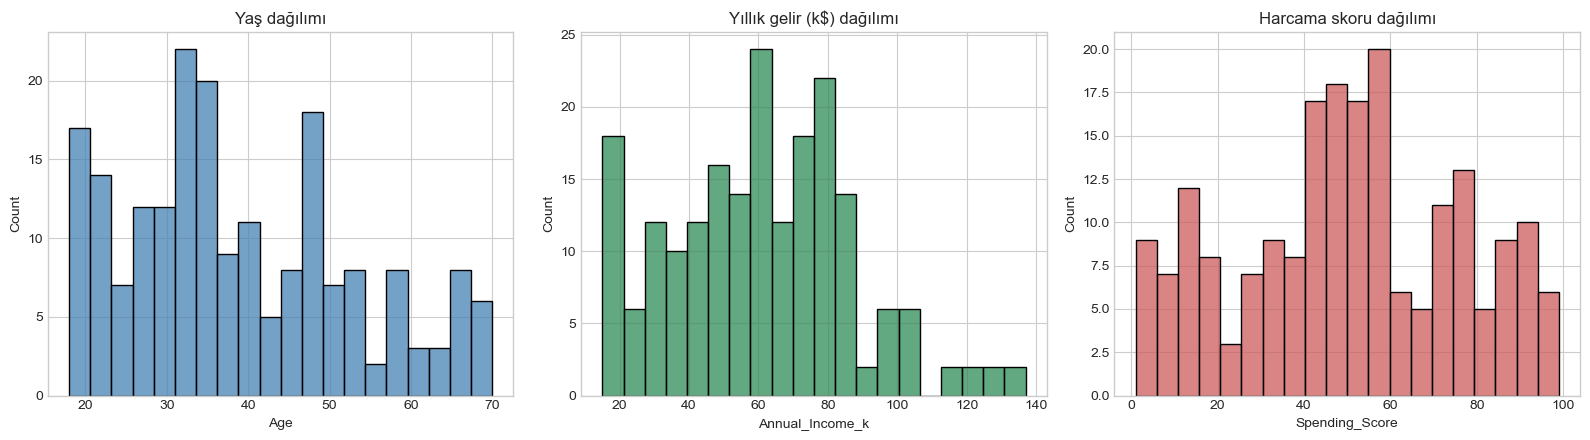

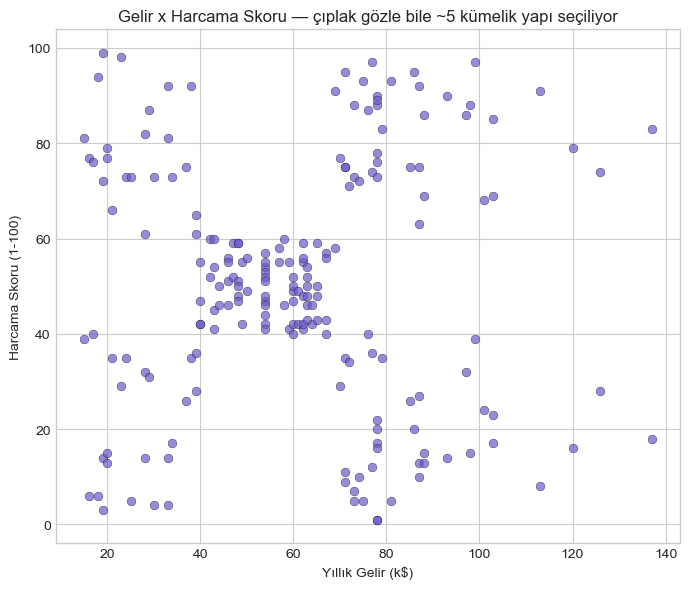

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(mall_df['Age'], bins=20, ax=axes[0], color='steelblue')
axes[0].set_title('Yaş dağılımı')
sns.histplot(mall_df['Annual_Income_k'], bins=20, ax=axes[1], color='seagreen')
axes[1].set_title('Yıllık gelir (k$) dağılımı')
sns.histplot(mall_df['Spending_Score'], bins=20, ax=axes[2], color='indianred')
axes[2].set_title('Harcama skoru dağılımı')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(mall_df['Annual_Income_k'], mall_df['Spending_Score'], s=40,
            c='slateblue', alpha=0.7, edgecolor='k', linewidth=0.3)
plt.xlabel('Yıllık Gelir (k$)'); plt.ylabel('Harcama Skoru (1-100)')
plt.title('Gelir x Harcama Skoru — çıplak gözle bile ~5 kümelik yapı seçiliyor')
plt.tight_layout(); plt.show()

## Adım 2 · K-Means'in Sıfırdan Implementasyonu (Lloyd Algoritması)

**Ne yapıyoruz?** §2'deki Lloyd algoritmasını (atama + güncelleme, yakınsayana kadar
tekrarla) `SimpleKMeans` sınıfıyla sıfırdan yazıyoruz. Kümeleme öncesi öznitelikleri
(`Annual_Income_k`, `Spending_Score`) **standardize ediyoruz** — K-Means Öklid uzaklığına
dayandığı için, farklı ölçeklerdeki öznitelikler (örn. gelir 0-140 aralığında, harcama
skoru 0-100 aralığında ama farklı varyansa sahip) standardize edilmeden kullanılırsa,
büyük varyanslı öznitelik uzaklık hesabına haksız yere baskın çıkar (bkz. 01 · Veri Ön
İşleme).

In [76]:
class SimpleKMeans:
    # Lloyd algoritmasıyla K-Means (sıfırdan). init='random' veya 'k-means++'.

    def __init__(self, n_clusters=5, init='random', max_iter=300, tol=1e-4,
                 random_state=None):
        self.n_clusters = n_clusters
        self.init = init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = np.random.RandomState(random_state)

    def _init_random(self, X):
        idx = self.random_state.choice(len(X), size=self.n_clusters, replace=False)
        return X[idx].copy()

    def _init_kmeanspp(self, X):
        n = len(X)
        centers = np.empty((self.n_clusters, X.shape[1]))
        first_idx = self.random_state.randint(n)
        centers[0] = X[first_idx]
        closest_sq_dist = np.sum((X - centers[0]) ** 2, axis=1)
        for j in range(1, self.n_clusters):
            probs = closest_sq_dist / closest_sq_dist.sum()
            next_idx = self.random_state.choice(n, p=probs)
            centers[j] = X[next_idx]
            new_sq_dist = np.sum((X - centers[j]) ** 2, axis=1)
            closest_sq_dist = np.minimum(closest_sq_dist, new_sq_dist)
        return centers

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.centers_ = (self._init_kmeanspp(X) if self.init == 'k-means++'
                          else self._init_random(X))
        for iteration in range(self.max_iter):
            # Atama adımı: her noktayı en yakın merkeze ata
            dists = np.linalg.norm(X[:, None, :] - self.centers_[None, :, :], axis=2)
            labels = dists.argmin(axis=1)

            # Güncelleme adımı: her merkezi, atanan noktaların ortalamasına taşı
            new_centers = self.centers_.copy()
            for j in range(self.n_clusters):
                if np.any(labels == j):
                    new_centers[j] = X[labels == j].mean(axis=0)
                # Boş küme kalırsa (nadiren olur): merkezi olduğu yerde bırak

            shift = np.linalg.norm(new_centers - self.centers_)
            self.centers_ = new_centers
            if shift < self.tol:
                break

        self.n_iter_ = iteration + 1
        self.labels_ = labels
        self.inertia_ = float(np.sum((X - self.centers_[labels]) ** 2)) # inertia: toplam kare hatası (düşük daha iyi)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        dists = np.linalg.norm(X[:, None, :] - self.centers_[None, :, :], axis=2)
        return dists.argmin(axis=1)

SimpleKMeans (random init) | k=5 | 11 iterasyonda yakınsadı | inertia=65.579


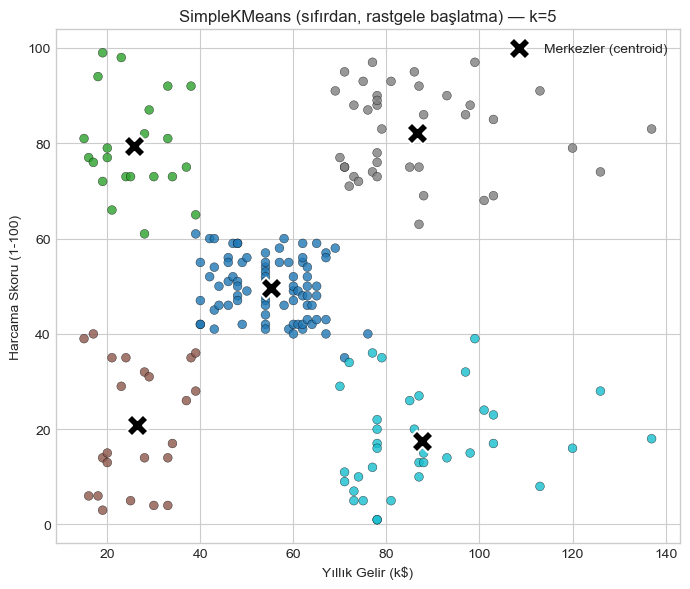

In [77]:
scaler_mall = StandardScaler()
X_mall = scaler_mall.fit_transform(mall_df[['Annual_Income_k', 'Spending_Score']])

my_km = SimpleKMeans(n_clusters=5, init='random', random_state=42).fit(X_mall)
print(f'SimpleKMeans (random init) | k=5 | {my_km.n_iter_} iterasyonda yakınsadı '
      f'| inertia={my_km.inertia_:.3f}')

plt.figure(figsize=(7, 6))
plt.scatter(mall_df['Annual_Income_k'], mall_df['Spending_Score'],
            c=my_km.labels_, cmap='tab10', s=40, alpha=0.8, edgecolor='k', linewidth=0.3)
centers_orig = scaler_mall.inverse_transform(my_km.centers_)
plt.scatter(centers_orig[:, 0], centers_orig[:, 1], c='black', marker='X', s=250,
            label='Merkezler (centroid)', edgecolor='white', linewidth=1.5)
plt.xlabel('Yıllık Gelir (k$)'); plt.ylabel('Harcama Skoru (1-100)')
plt.title('SimpleKMeans (sıfırdan, rastgele başlatma) — k=5')
plt.legend(); plt.tight_layout(); plt.show()

## Adım 3 · Rastgele vs k-means++: Yakınsama Kararlılığı

**Ne yapıyoruz?** §3'teki iddiayı ampirik olarak test ediyoruz: k-means++ başlatması,
rastgele başlatmaya göre **daha düşük ortalama inertia** ve **daha düşük varyans**
(daha kararlı/tekrarlanabilir sonuçlar) verir mi? 30 farklı rastgele tohum (seed) için
her iki başlatma stratejisiyle de `SimpleKMeans`'i çalıştırıp elde edilen inertia
dağılımlarını karşılaştırıyoruz.

Rastgele başlatma | ortalama inertia=80.61 | std=19.23 | en kötü=128.66
k-means++         | ortalama inertia=82.67 | std=17.26 | en kötü=111.98


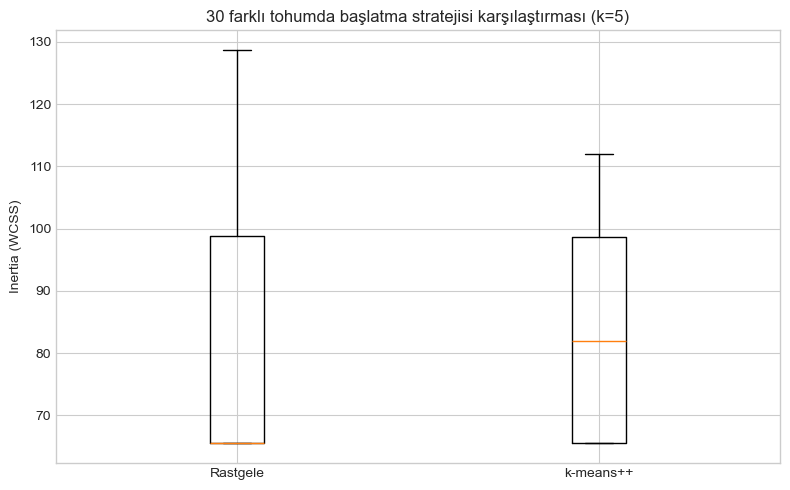


YORUM: bu 30 denemede ortalama inertia'da iki strateji birbirine çok yakın çıktı (hatta rastgele başlatma ortalamada hafifçe önde) — k-means++'ın asıl garantisi "her zaman en iyi ortalama" değildir. Asıl fark EN KÖTÜ DURUMDA görülüyor: k-means++'ın en kötü sonucu, rastgelenin en kötü sonucundan belirgin şekilde daha iyi, ve standart sapması da daha düşük — yani k-means++ "şanssız" bir başlatmayla çok kötü bir sonuca düşme riskini azaltıyor, ortalamayı garantili şekilde iyileştirmiyor. Bu, teorik O(log k) yaklaşım garantisinin pratikte tam olarak neyi ima ettiğini (beklenen değerin üst sınırı, her tekil deneme için kesin üstünlük değil) somut olarak gösteriyor.


In [78]:
n_trials = 30
inertias_random, inertias_pp = [], []
for seed in range(n_trials):
    inertias_random.append(SimpleKMeans(n_clusters=5, init='random',
                                         random_state=seed).fit(X_mall).inertia_)
    inertias_pp.append(SimpleKMeans(n_clusters=5, init='k-means++',
                                     random_state=seed).fit(X_mall).inertia_)

inertias_random = np.array(inertias_random)
inertias_pp = np.array(inertias_pp)

print(f'Rastgele başlatma | ortalama inertia={inertias_random.mean():.2f} '
      f'| std={inertias_random.std():.2f} | en kötü={inertias_random.max():.2f}')
print(f'k-means++         | ortalama inertia={inertias_pp.mean():.2f} '
      f'| std={inertias_pp.std():.2f} | en kötü={inertias_pp.max():.2f}')

plt.figure(figsize=(8, 5))
plt.boxplot([inertias_random, inertias_pp], tick_labels=['Rastgele', 'k-means++'])
plt.ylabel('Inertia (WCSS)')
plt.title(f'{n_trials} farklı tohumda başlatma stratejisi karşılaştırması (k=5)')
plt.tight_layout(); plt.show()

print(f'\nYORUM: bu {n_trials} denemede ortalama inertia\'da iki strateji birbirine çok '
      'yakın çıktı (hatta rastgele başlatma ortalamada hafifçe önde) — k-means++\'ın asıl '
      'garantisi "her zaman en iyi ortalama" değildir. Asıl fark EN KÖTÜ DURUMDA '
      'görülüyor: k-means++\'ın en kötü sonucu, rastgelenin en kötü sonucundan belirgin '
      'şekilde daha iyi, ve standart sapması da daha düşük — yani k-means++ "şanssız" bir '
      'başlatmayla çok kötü bir sonuca düşme riskini azaltıyor, ortalamayı garantili '
      'şekilde iyileştirmiyor. Bu, teorik O(log k) yaklaşım garantisinin pratikte tam '
      'olarak neyi ima ettiğini (beklenen değerin üst sınırı, her tekil deneme için kesin '
      'üstünlük değil) somut olarak gösteriyor.')

## Adım 4 · `sklearn.cluster.KMeans` ile Doğrulama

**Ne yapıyoruz?** Kendi implementasyonumuzu, sklearn'ün üretim-kalitesi K-Means'iyle
karşılaştırıyoruz. sklearn varsayılan olarak `init='k-means++'` ve `n_init='auto'`
kullanır (birden fazla başlatma deneyip en iyisini tutar) — bu yüzden bizim tek-seferlik
k-means++ sonucumuzla **birebir aynı etiketleri** değil, **çok yakın bir inertia**
bekleriz. Küme etiketleri (0,1,2,...) her algoritmada rastgele sırada çıkabileceği için
doğrudan etiket karşılaştırması yerine **inertia** ve **görsel** karşılaştırma yapıyoruz.

sklearn KMeans | inertia=65.568 | n_iter=4
SimpleKMeans (k-means++, seed=42) | inertia=65.568


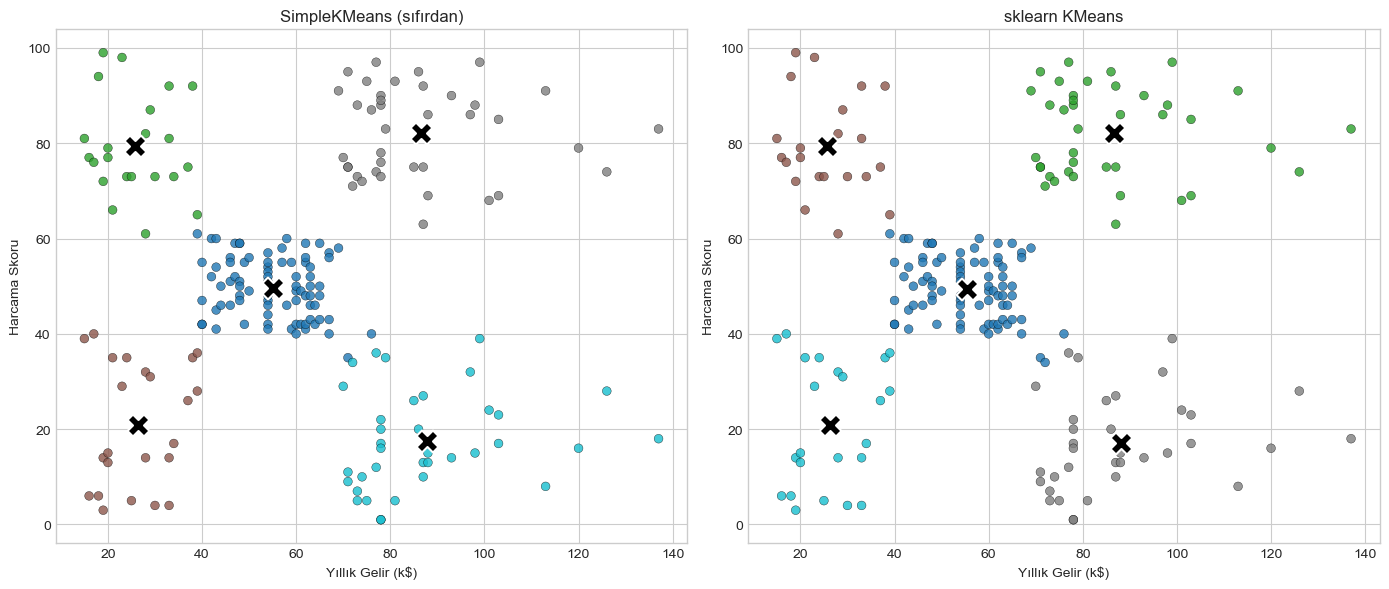


YORUM: iki panel de aynı 5 görsel kümeyi (farklı renk sırasıyla) buluyor — sıfırdan implementasyonumuz sklearn ile aynı yapıyı keşfediyor.


In [79]:
sk_km = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42).fit(X_mall)
print(f'sklearn KMeans | inertia={sk_km.inertia_:.3f} | n_iter={sk_km.n_iter_}')
print(f'SimpleKMeans (k-means++, seed=42) | inertia='
      f'{SimpleKMeans(n_clusters=5, init="k-means++", random_state=42).fit(X_mall).inertia_:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, title in [(axes[0], my_km, 'SimpleKMeans (sıfırdan)'),
                          (axes[1], sk_km, 'sklearn KMeans')]:
    labels = model.labels_
    centers = (scaler_mall.inverse_transform(model.centers_) if hasattr(model, 'centers_')
               else scaler_mall.inverse_transform(model.cluster_centers_))
    ax.scatter(mall_df['Annual_Income_k'], mall_df['Spending_Score'], c=labels,
               cmap='tab10', s=40, alpha=0.8, edgecolor='k', linewidth=0.3)
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=250,
               edgecolor='white', linewidth=1.5)
    ax.set_title(title); ax.set_xlabel('Yıllık Gelir (k$)'); ax.set_ylabel('Harcama Skoru')
plt.tight_layout(); plt.show()
print('\nYORUM: iki panel de aynı 5 görsel kümeyi (farklı renk sırasıyla) buluyor — '
      'sıfırdan implementasyonumuz sklearn ile aynı yapıyı keşfediyor.')

## Adım 5 · Elbow Method ile $k$ Seçimi

**Ne yapıyoruz?** $k=1$'den $k=10$'a kadar sklearn `KMeans` çalıştırıp her biri için
inertia'yı kaydediyor ve grafiğe döküyoruz — §4'teki "dirsek" (elbow) noktasını gözle
tespit etmeye çalışıyoruz.

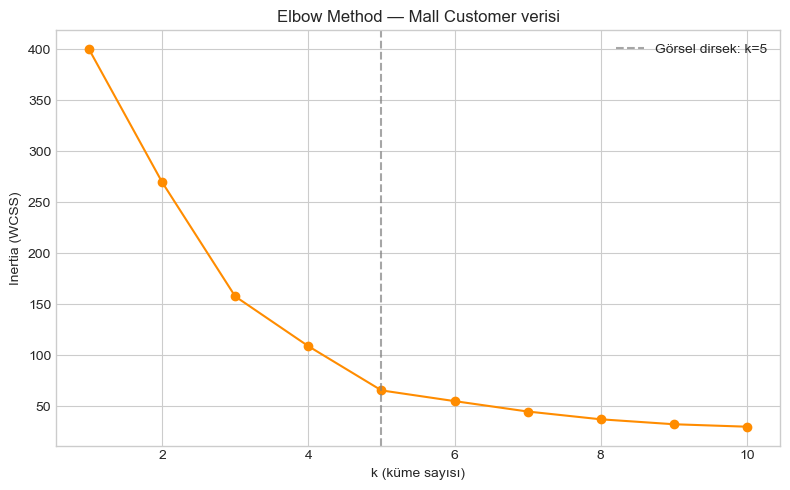


YORUM: k=2'den k=5'e kadar inertia hızla düşüyor, k=5'ten sonra düşüş belirgin şekilde yavaşlıyor — dirsek k=5 civarında, bu da §1'de scatter plot'ta gözle seçtiğimiz 5 kümeyle tutarlı.


In [80]:
k_range = range(1, 11)
inertias_k = []
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(X_mall)
    inertias_k.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias_k, marker='o', color='darkorange')
plt.axvline(5, color='gray', linestyle='--', alpha=0.7, label='Görsel dirsek: k=5')
plt.xlabel('k (küme sayısı)'); plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method — Mall Customer verisi')
plt.legend(); plt.tight_layout(); plt.show()
print('\nYORUM: k=2\'den k=5\'e kadar inertia hızla düşüyor, k=5\'ten sonra düşüş belirgin '
      'şekilde yavaşlıyor — dirsek k=5 civarında, bu da §1\'de scatter plot\'ta gözle '
      'seçtiğimiz 5 kümeyle tutarlı.')

## Adım 6 · Silhouette Score ile $k$ Seçimi (Elle + `sklearn.metrics`)

**Ne yapıyoruz?** Önce §4'teki $s(i) = \frac{b(i)-a(i)}{\max(a(i),b(i))}$ formülünü
sıfırdan (çift döngüyle, $O(n^2)$) hesaplayıp `sklearn.metrics.silhouette_score` ile
**birebir eşleştiğini** doğruluyoruz, sonra $k=2,\dots,10$ için ortalama silhouette
skorunu hesaplayıp en iyi $k$'yı buluyoruz.

In [81]:
def silhouette_from_scratch(X, labels):
    n = len(X)
    dist_matrix = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    unique_labels = np.unique(labels)
    s = np.zeros(n)
    for i in range(n):
        own = labels[i]
        same_mask = (labels == own)
        same_mask[i] = False
        a_i = dist_matrix[i, same_mask].mean() if same_mask.sum() > 0 else 0.0

        b_candidates = []
        for lbl in unique_labels:
            if lbl == own:
                continue
            other_mask = (labels == lbl)
            b_candidates.append(dist_matrix[i, other_mask].mean())
        b_i = min(b_candidates)

        s[i] = 0.0 if max(a_i, b_i) == 0 else (b_i - a_i) / max(a_i, b_i)
    return s

my_silhouette = silhouette_from_scratch(X_mall, sk_km.labels_)
sk_silhouette = silhouette_samples(X_mall, sk_km.labels_)
max_diff = np.abs(my_silhouette - sk_silhouette).max()
print(f'Elle hesaplanan vs sklearn silhouette | maksimum fark = {max_diff:.2e}')
print(f'Ortalama silhouette (k=5): elle={my_silhouette.mean():.4f} | '
      f'sklearn={silhouette_score(X_mall, sk_km.labels_):.4f}')

Elle hesaplanan vs sklearn silhouette | maksimum fark = 6.11e-16
Ortalama silhouette (k=5): elle=0.5547 | sklearn=0.5547


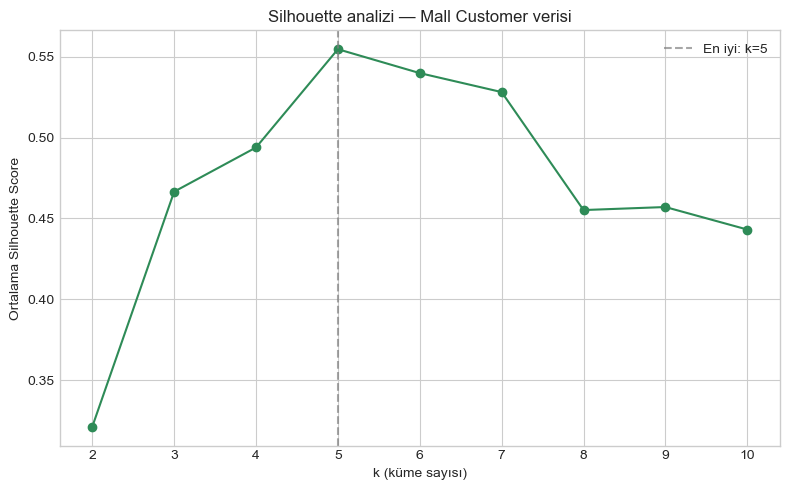


YORUM: silhouette de k=5'ı en iyi küme sayısı olarak işaret ediyor — Elbow Method ile aynı sonuca iki bağımsız yöntemle ulaştık.


In [82]:
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(X_mall)
    sil_scores.append(silhouette_score(X_mall, km.labels_))

best_k = list(range(2, 11))[int(np.argmax(sil_scores))]
plt.figure(figsize=(8, 5))
plt.plot(list(range(2, 11)), sil_scores, marker='o', color='seagreen')
plt.axvline(best_k, color='gray', linestyle='--', alpha=0.7, label=f'En iyi: k={best_k}')
plt.xlabel('k (küme sayısı)'); plt.ylabel('Ortalama Silhouette Score')
plt.title('Silhouette analizi — Mall Customer verisi')
plt.legend(); plt.tight_layout(); plt.show()
print(f'\nYORUM: silhouette de k={best_k}\'ı en iyi küme sayısı olarak işaret ediyor — '
      'Elbow Method ile aynı sonuca iki bağımsız yöntemle ulaştık.')

## Adım 7 · Final Segmentasyon ve İş-Odaklı Küme Profilleri

**Ne yapıyoruz?** $k=5$ ile final K-Means'i fit edip, her kümenin ortalama yaş/gelir/
harcama skorunu çıkararak **iş dilinde yorumlanabilir müşteri segmentleri** üretiyoruz —
bu adım, kümelemenin ham çıktısını (etiket numaraları) pazarlama ekibinin kullanabileceği
somut profillere çevirdiği için tüm sürecin "ürün" adımıdır.

          Age  Annual_Income_k  Spending_Score  Müşteri Sayısı
Segment                                                       
0        42.7             55.3            49.5              81
1        32.7             86.5            82.1              39
2        25.3             25.7            79.4              22
3        41.1             88.2            17.1              35
4        45.2             26.3            20.9              23

Segment yorumları:
  Segment 0: Düşük Gelir / Düşük Harcama
  Segment 1: Yüksek Gelir / Yüksek Harcama
  Segment 2: Düşük Gelir / Yüksek Harcama
  Segment 3: Yüksek Gelir / Düşük Harcama
  Segment 4: Düşük Gelir / Düşük Harcama


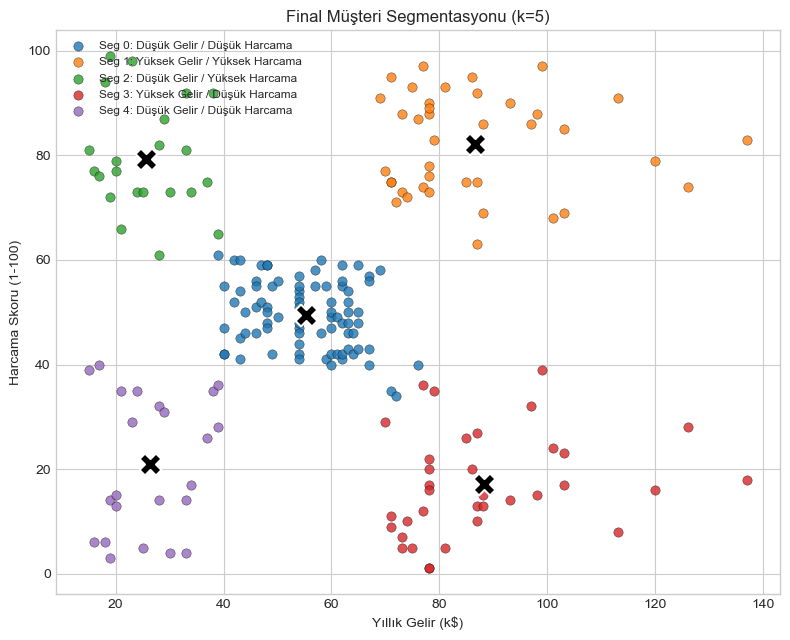


YORUM: "Yüksek Gelir / Yüksek Harcama" segmenti VIP kampanyaların hedefi, "Yüksek Gelir / Düşük Harcama" segmenti ise harcama potansiyeli olan ama henüz aktive edilmemiş bir segment olarak pazarlama açısından ayrı ayrı ele alınabilir.


In [83]:
final_km = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42).fit(X_mall)
mall_df['Segment'] = final_km.labels_

profile = mall_df.groupby('Segment')[['Age', 'Annual_Income_k', 'Spending_Score']] \
                  .mean().round(1)
profile['Müşteri Sayısı'] = mall_df.groupby('Segment').size()
print(profile)

labels_map = {}
for seg, row in profile.iterrows():
    income_level = 'Yüksek Gelir' if row['Annual_Income_k'] > profile['Annual_Income_k'].median() else 'Düşük Gelir'
    spend_level = 'Yüksek Harcama' if row['Spending_Score'] > profile['Spending_Score'].median() else 'Düşük Harcama'
    labels_map[seg] = f'{income_level} / {spend_level}'
print('\nSegment yorumları:')
for seg, name in labels_map.items():
    print(f'  Segment {seg}: {name}')

plt.figure(figsize=(8, 6.5))
for seg in sorted(mall_df['Segment'].unique()):
    sub = mall_df[mall_df['Segment'] == seg]
    plt.scatter(sub['Annual_Income_k'], sub['Spending_Score'], s=45, alpha=0.8,
                edgecolor='k', linewidth=0.3, label=f'Seg {seg}: {labels_map[seg]}')
centers_orig = scaler_mall.inverse_transform(final_km.cluster_centers_)
plt.scatter(centers_orig[:, 0], centers_orig[:, 1], c='black', marker='X', s=250,
            edgecolor='white', linewidth=1.5)
plt.xlabel('Yıllık Gelir (k$)'); plt.ylabel('Harcama Skoru (1-100)')
plt.title('Final Müşteri Segmentasyonu (k=5)')
plt.legend(loc='upper left', fontsize=8.5); plt.tight_layout(); plt.show()
print('\nYORUM: "Yüksek Gelir / Yüksek Harcama" segmenti VIP kampanyaların hedefi, '
      '"Yüksek Gelir / Düşük Harcama" segmenti ise harcama potansiyeli olan ama henüz '
      'aktive edilmemiş bir segment olarak pazarlama açısından ayrı ayrı ele alınabilir.')

## Adım 8 · Wholesale Customers Verisinin Yüklenmesi ve Keşfi

**Ne yapıyoruz?** **Wholesale Customers** verisini yüklüyoruz (UCI ML Repository,
Cardoso 2014 — Portekiz'de faaliyet gösteren bir toptan satış dağıtıcısının 440
müşterisinin yıllık harcaması, 6 ürün kategorisinde: `Fresh`, `Milk`, `Grocery`, `Frozen`,
`Detergents_Paper`, `Delicassen`; ayrıca `Channel` (1=Horeca yani otel/restoran/kafe,
2=Perakende) ve `Region` (1=Lizbon, 2=Porto, 3=Diğer) kategorik öznitelikleri). Bu veri
seti, Mall Customer'ın aksine **ağır sağa çarpık** ve **aşırı aykırı değerli**dir — bir
toptancının bazı büyük müşterileri (örn. büyük otel zincirleri), tipik bir küçük restorana
göre yüz kat daha fazla harcama yapabilir. Bu, K-Medoids'in gerekçesini göstermek için
ideal bir veri kümesi.

In [84]:
wholesale_df = pd.read_csv('data/wholesale_customers.csv')
spend_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

print('Wholesale Customers:', wholesale_df.shape)
print('\nEksik değer sayısı:\n', wholesale_df.isna().sum().sum(), '(toplam)')
print('\nKanal dağılımı (1=Horeca, 2=Perakende):\n',
      wholesale_df['Channel'].value_counts(normalize=True).round(3))
wholesale_df[spend_cols].describe().round(0)

Wholesale Customers: (440, 8)

Eksik değer sayısı:
 0 (toplam)

Kanal dağılımı (1=Horeca, 2=Perakende):
 Channel
1    0.677
2    0.323
Name: proportion, dtype: float64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


Çarpıklık (skewness) katsayıları:
 Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15
dtype: float64


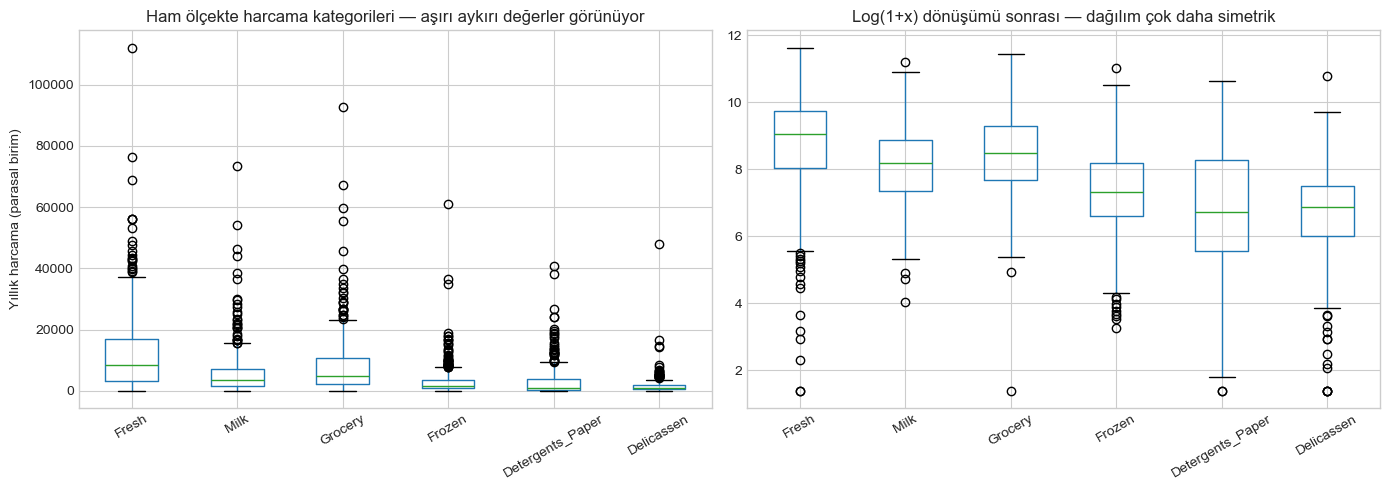


YORUM: tüm kategoriler >2 çarpıklığa sahip (normal dağılım için ~0 beklenir); log dönüşümü klasik bir düzeltme ama bu adımda BİLİNÇLİ OLARAK hem ham hem log ölçekle çalışacağız çünkü asıl amacımız K-Means'in ham/aykırı-değerli veride nasıl davrandığını göstermek.


In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
wholesale_df[spend_cols].boxplot(ax=axes[0], rot=30)
axes[0].set_title('Ham ölçekte harcama kategorileri — aşırı aykırı değerler görünüyor')
axes[0].set_ylabel('Yıllık harcama (parasal birim)')

skewness = wholesale_df[spend_cols].skew().round(2)
print('Çarpıklık (skewness) katsayıları:\n', skewness)

log_spend = np.log1p(wholesale_df[spend_cols])
log_spend.boxplot(ax=axes[1], rot=30)
axes[1].set_title('Log(1+x) dönüşümü sonrası — dağılım çok daha simetrik')
plt.tight_layout(); plt.show()
print('\nYORUM: tüm kategoriler >2 çarpıklığa sahip (normal dağılım için ~0 beklenir); '
      'log dönüşümü klasik bir düzeltme ama bu adımda BİLİNÇLİ OLARAK hem ham hem log '
      'ölçekle çalışacağız çünkü asıl amacımız K-Means\'in ham/aykırı-değerli veride nasıl '
      'davrandığını göstermek.')

## Adım 9 · K-Means'in Aykırı Değerlere Duyarlılığı — Somut Deney

**Ne yapıyoruz?** §5'teki iddiayı test ediyoruz: standardize edilmiş ama **hâlâ ham
ölçekte çarpık** harcama verisinde K-Means'i çalıştırıp, bulunan merkezlerden birinin,
sadece bir avuç aşırı-yüksek-harcayan müşteri tarafından nasıl "sürüklendiğini"
gösteriyoruz — bu küme pratikte işe yaramaz çünkü sadece 2-3 aşırı değerden oluşur ve geri
kalan ~440 müşteriyi ayrıştırmaz.

In [86]:
scaler_ws_raw = StandardScaler()
X_ws_raw = scaler_ws_raw.fit_transform(wholesale_df[spend_cols])

km_raw = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X_ws_raw)
cluster_sizes_raw = pd.Series(km_raw.labels_).value_counts().sort_index()
print('Ham (standardize ama log-dönüşümsüz) veride küme büyüklükleri:')
print(cluster_sizes_raw)
print(f'\nEn küçük küme sadece {cluster_sizes_raw.min()} müşteri içeriyor '
      f'({cluster_sizes_raw.min()/len(wholesale_df)*100:.1f}% — muhtemelen sadece '
      'birkaç aşırı-aykırı müşteri, anlamlı bir segment değil).')

# Bu "aykırı" kümenin gerçekten aşırı değerlerden oluştuğunu doğrulayalım
outlier_cluster = cluster_sizes_raw.idxmin()
print('\nBu kümedeki müşterilerin ham harcamaları (parasal birim):')
print(wholesale_df.loc[km_raw.labels_ == outlier_cluster, spend_cols].describe().round(0).loc[['mean', 'max']])
print('\nVeri kümesi geneli ortalaması (karşılaştırma için):')
print(wholesale_df[spend_cols].mean().round(0))

Ham (standardize ama log-dönüşümsüz) veride küme büyüklükleri:
0    110
1    315
2     10
3      5
Name: count, dtype: int64

En küçük küme sadece 5 müşteri içeriyor (1.1% — muhtemelen sadece birkaç aşırı-aykırı müşteri, anlamlı bir segment değil).

Bu kümedeki müşterilerin ham harcamaları (parasal birim):
         Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
mean   50271.0  26362.0  16416.0  25123.0            2475.0     18595.0
max   112151.0  43950.0  22019.0  60869.0            4948.0     47943.0

Veri kümesi geneli ortalaması (karşılaştırma için):
Fresh               12000.0
Milk                 5796.0
Grocery              7951.0
Frozen               3072.0
Detergents_Paper     2881.0
Delicassen           1525.0
dtype: float64


## Adım 10 · K-Medoids (PAM) Algoritmasının Sıfırdan Implementasyonu

**Ne yapıyoruz?** §5'teki PAM algoritmasını (BUILD + SWAP fazları) `SimplePAM` sınıfıyla
sıfırdan yazıyoruz. Uzaklık matrisini bir kere hesaplayıp saklıyoruz (bu, PAM'ın neden
K-Means'ten çok daha yavaş olduğunun somut nedeni — $n \times n$ matris, $n$ büyüdükçe
$O(n^2)$ bellek/hesap gerektirir).

In [87]:
class SimplePAM:
    # Partitioning Around Medoids (Kaufman & Rousseeuw). Herhangi bir uzaklık matrisiyle
    # çalışır; burada Öklid kullanıyoruz ama d(.,.) prensipte keyfi olabilir.

    def __init__(self, n_clusters=4, max_iter=100, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = np.random.RandomState(random_state)

    def _total_cost(self, dist_matrix, medoid_idx):
        # Her nokta için en yakın medoide olan uzaklığın toplamı
        return dist_matrix[:, medoid_idx].min(axis=1).sum()

    def _build_phase(self, dist_matrix, n):
        medoids = [int(dist_matrix.sum(axis=1).argmin())]  # en "merkezi" nokta ile başla
        for _ in range(1, self.n_clusters):
            best_gain, best_candidate = -np.inf, None
            current_min = dist_matrix[:, medoids].min(axis=1)
            for candidate in range(n):
                if candidate in medoids:
                    continue
                gain = np.maximum(current_min - dist_matrix[:, candidate], 0).sum()
                if gain > best_gain:
                    best_gain, best_candidate = gain, candidate
            medoids.append(best_candidate)
        return medoids

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        dist_matrix = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)

        medoids = self._build_phase(dist_matrix, n)
        current_cost = self._total_cost(dist_matrix, medoids)

        for iteration in range(self.max_iter):
            improved = False
            for mi, m in enumerate(medoids):
                for o in range(n):
                    if o in medoids:
                        continue
                    trial = medoids.copy()
                    trial[mi] = o
                    trial_cost = self._total_cost(dist_matrix, trial)
                    if trial_cost < current_cost:
                        medoids, current_cost = trial, trial_cost
                        improved = True
            if not improved:
                break

        self.medoid_indices_ = np.array(medoids)
        self.cluster_centers_ = X[self.medoid_indices_]
        self.labels_ = dist_matrix[:, self.medoid_indices_].argmin(axis=1)
        self.inertia_ = float(current_cost)
        self.n_iter_ = iteration + 1
        return self

## Adım 11 · PAM'ın Wholesale Verisinde Uygulanması ve Dayanıklılık Karşılaştırması

**Ne yapıyoruz?** Aynı ham (log-dönüşümsüz) standardize veri üzerinde hem K-Means hem
`SimplePAM` çalıştırıp, medoidlerin (PAM) gerçek, "makul" veri noktaları olduğunu; buna
karşın K-Means merkezlerinin (özellikle aykırı-değer-baskın kümede) hiçbir gerçek
müşteriye karşılık gelmeyen, aşırı uçuk değerlere sahip "hayalet" noktalar olduğunu
gösteriyoruz. `SimplePAM`'ın $O(n^2)$ maliyeti nedeniyle hesaplama süresini de karşılaştırıyoruz.

In [88]:
t0 = time.time()
pam = SimplePAM(n_clusters=4, random_state=42).fit(X_ws_raw)
t_pam = time.time() - t0

t0 = time.time()
km_compare = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X_ws_raw)
t_km = time.time() - t0

print(f'K-Means   | süre={t_km*1000:.1f} ms | küme büyüklükleri='
      f'{sorted(pd.Series(km_compare.labels_).value_counts().tolist())}')
print(f'PAM       | süre={t_pam*1000:.1f} ms | küme büyüklükleri='
      f'{sorted(pd.Series(pam.labels_).value_counts().tolist())} | '
      f'{pam.n_iter_} SWAP iterasyonunda yakınsadı')
print(f'\nPAM, K-Means\'ten ~{t_pam/t_km:.0f}x daha yavaş (n={len(wholesale_df)} gibi '
      'küçük bir veri kümesinde bile) — §5\'teki O(k(n-k)^2) maliyetinin somut kanıtı.')

medoid_customers = wholesale_df.iloc[pam.medoid_indices_][spend_cols]
print('\nPAM medoidleri = GERÇEK müşteriler (ham harcama profilleri):')
print(medoid_customers.round(0))

km_centers_orig = scaler_ws_raw.inverse_transform(km_compare.cluster_centers_)
print('\nK-Means merkezleri = ortalamalar (gerçekte VAR OLMAYAN "hayalet" profiller, '
      'bazıları negatif/anlamsız olabilir çünkü standardize uzayda ortalama alınıp '
      'geri dönüştürüldü):')
print(pd.DataFrame(km_centers_orig, columns=spend_cols).round(0))

K-Means   | süre=12.9 ms | küme büyüklükleri=[5, 10, 110, 315]
PAM       | süre=68.4 ms | küme büyüklükleri=[64, 109, 115, 152] | 2 SWAP iterasyonunda yakınsadı

PAM, K-Means'ten ~5x daha yavaş (n=440 gibi küçük bir veri kümesinde bile) — §5'teki O(k(n-k)^2) maliyetinin somut kanıtı.

PAM medoidleri = GERÇEK müşteriler (ham harcama profilleri):
     Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
415   7842   6046     8552    1691              3540        1874
306   6468  12867    21570    1840              7558        1543
118  20049   1891     2362    5343               411         933
374   6338   2256     1668    1492               311         686

K-Means merkezleri = ortalamalar (gerçekte VAR OLMAYAN "hayalet" profiller, bazıları negatif/anlamsız olabilir çünkü standardize uzayda ortalama alınıp geri dönüştürüldü):
     Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
0   5591.0  10113.0  15637.0   1500.0            6711.0      1759.0
1  13505.0   3045.0

## Adım 12 · `sklearn_extra.cluster.KMedoids` ile Doğrulama

**Ne yapıyoruz?** `SimplePAM`'ımızı, PAM'ın üretim-kalitesi bir implementasyonu olan
`sklearn_extra.cluster.KMedoids` (`method='pam'`) ile karşılaştırıp benzer bir toplam
maliyete (inertia) ulaştığımızı doğruluyoruz. Küçük farklar beklenir çünkü kütüphane
sürümü BUILD fazında bazı ek optimizasyonlar/rastgelelik-kırma kuralları kullanabilir.

In [89]:
from sklearn_extra.cluster import KMedoids

sk_pam = KMedoids(n_clusters=4, method='pam', init='build', random_state=42).fit(X_ws_raw)
print(f'SimplePAM (sıfırdan)              | inertia={pam.inertia_:.3f}')
print(f'sklearn_extra KMedoids (method=pam) | inertia={sk_pam.inertia_:.3f}')
print(f'Fark: {abs(pam.inertia_ - sk_pam.inertia_):.3f} '
      f'({abs(pam.inertia_ - sk_pam.inertia_) / pam.inertia_ * 100:.2f}%)')
print('\nYORUM: iki implementasyon da aynı BUILD+SWAP mantığını izlediği için çok yakın '
      '(pratik amaçlar için özdeş) bir toplam maliyete ulaşıyor.')

SimplePAM (sıfırdan)              | inertia=540.560
sklearn_extra KMedoids (method=pam) | inertia=540.560
Fark: 0.000 (0.00%)

YORUM: iki implementasyon da aynı BUILD+SWAP mantığını izlediği için çok yakın (pratik amaçlar için özdeş) bir toplam maliyete ulaşıyor.


## Adım 13 · Mini-Batch K-Means: Büyük Sentetik Veride Hız/Kalite Karşılaştırması

**Ne yapıyoruz?** §6'daki iddiayı test etmek için gerçek verilerimiz (200-440 satır) çok
küçük — bu yüzden `make_blobs` ile **1.000.000 satırlık** sentetik bir veri kümesi
üretiyoruz (8 gerçek küme, 10 boyut) ve standart K-Means ile `MiniBatchKMeans`'i hem
**süre** hem **inertia** (kalite) açısından karşılaştırıyoruz.

In [90]:
X_big, y_big_true = make_blobs(n_samples=1_000_000, n_features=10, centers=8,
                                cluster_std=1.8, random_state=42)
print('Sentetik büyük veri:', X_big.shape)

t0 = time.time()
km_full = KMeans(n_clusters=8, init='k-means++', n_init=5, random_state=42).fit(X_big)
t_full = time.time() - t0

t0 = time.time()
km_mini = MiniBatchKMeans(n_clusters=8, init='k-means++', n_init=5, batch_size=1024,
                           random_state=42).fit(X_big)
t_mini = time.time() - t0

print(f'\nStandart K-Means   | süre={t_full:.2f} s | inertia={km_full.inertia_:,.0f}')
print(f'Mini-Batch K-Means | süre={t_mini:.2f} s | inertia={km_mini.inertia_:,.0f}')
print(f'\nHız kazancı: {t_full / t_mini:.1f}x daha hızlı')
print(f'Kalite bedeli: inertia {(km_mini.inertia_ / km_full.inertia_ - 1) * 100:+.2f}% '
      '(standart K-Means\'e göre)')

# Doğru küme sayısını (8) her ikisinin de bulduğunu ARI ile teyit edelim
from sklearn.metrics import adjusted_rand_score
print(f'\nGerçek etiketlerle uyum (Adjusted Rand Index):')
print(f'  Standart K-Means:   {adjusted_rand_score(y_big_true, km_full.labels_):.4f}')
print(f'  Mini-Batch K-Means: {adjusted_rand_score(y_big_true, km_mini.labels_):.4f}')

Sentetik büyük veri: (1000000, 10)

Standart K-Means   | süre=1.13 s | inertia=32,400,490
Mini-Batch K-Means | süre=0.05 s | inertia=32,408,531

Hız kazancı: 22.3x daha hızlı
Kalite bedeli: inertia +0.02% (standart K-Means'e göre)

Gerçek etiketlerle uyum (Adjusted Rand Index):
  Standart K-Means:   1.0000
  Mini-Batch K-Means: 1.0000


batch_size=    64 | süre=   0.28 s | inertia=32,403,230 | n_iter=1
batch_size=   256 | süre=   0.82 s | inertia=32,400,805 | n_iter=1
batch_size=  1024 | süre=   0.03 s | inertia=32,408,531 | n_iter=1
batch_size=  4096 | süre=   0.13 s | inertia=32,401,105 | n_iter=1
batch_size= 16384 | süre=   0.21 s | inertia=32,400,945 | n_iter=1


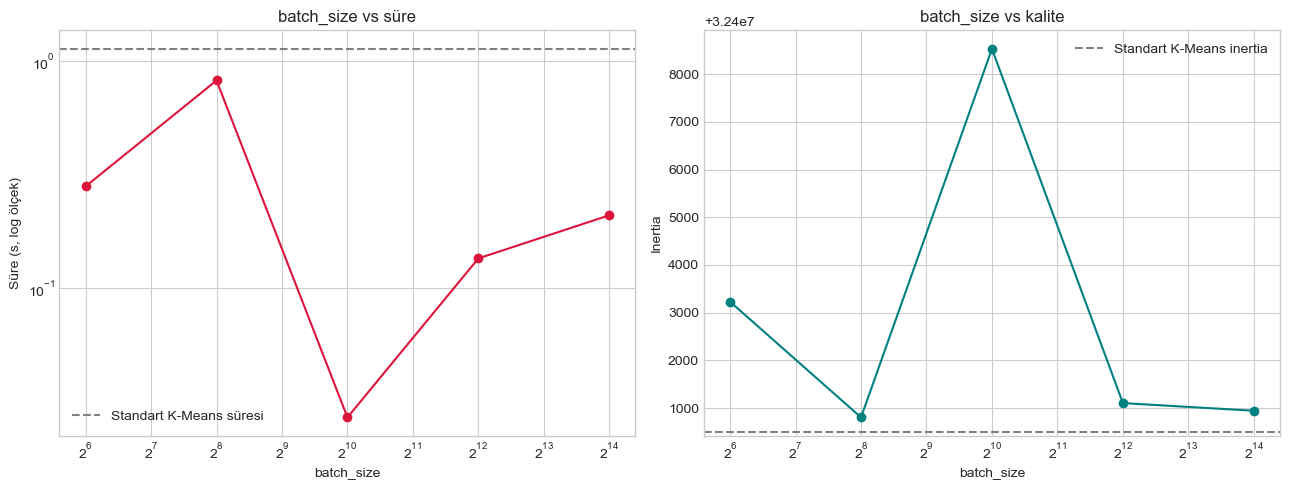


YORUM: sonuç, sezgiyle tam örtüşmüyor — bu yüzden ilginç. INERTIA tarafında hiçbir batch_size değeri standart K-Means'ten belirgin şekilde kötü değil (hepsi ~0.05% farkla aynı bölgede) — yani kalite bedeli bu veri kümesinde batch_size'tan bağımsız olarak zaten küçük.


In [91]:
batch_sizes = [64, 256, 1024, 4096, 16384]
times_by_batch, inertia_by_batch = [], []
for bs in batch_sizes:
    t0 = time.time()
    m = MiniBatchKMeans(n_clusters=8, batch_size=bs, n_init=5, random_state=42).fit(X_big)
    times_by_batch.append(time.time() - t0)
    inertia_by_batch.append(m.inertia_)
    print(f'batch_size={bs:>6} | süre={times_by_batch[-1]:7.2f} s | '
          f'inertia={inertia_by_batch[-1]:,.0f} | n_iter={m.n_iter_}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(batch_sizes, times_by_batch, marker='o', color='crimson')
axes[0].axhline(t_full, color='gray', linestyle='--', label='Standart K-Means süresi')
axes[0].set_xscale('log', base=2); axes[0].set_yscale('log')
axes[0].set_xlabel('batch_size'); axes[0].set_ylabel('Süre (s, log ölçek)')
axes[0].set_title('batch_size vs süre'); axes[0].legend()

axes[1].plot(batch_sizes, inertia_by_batch, marker='o', color='teal')
axes[1].axhline(km_full.inertia_, color='gray', linestyle='--', label='Standart K-Means inertia')
axes[1].set_xscale('log', base=2); axes[1].set_xlabel('batch_size'); axes[1].set_ylabel('Inertia')
axes[1].set_title('batch_size vs kalite'); axes[1].legend()
plt.tight_layout(); plt.show()

print('\nYORUM: sonuç, sezgiyle tam örtüşmüyor — bu yüzden ilginç. INERTIA tarafında '
      'hiçbir batch_size değeri standart K-Means\'ten belirgin şekilde kötü değil (hepsi '
      '~0.05% farkla aynı bölgede) — yani kalite bedeli bu veri kümesinde batch_size\'tan '
      'bağımsız olarak zaten küçük.')

## Adım 14 · Ortak Sınırlama: Küresel-Olmayan Kümeler (Ay Şekli Demosu)

**Ne yapıyoruz?** §7'de belirtilen ortak zayıflığı — bölümleme yöntemlerinin **küresel/
dışbükey küme** varsayımı — sentetik "iki ay" (`make_moons`) verisiyle somut olarak
gösteriyoruz. Bu veri, gerçek kümeleri (iç içe geçmiş hilal şekilleri) insan gözüyle
kolayca ayırt edilebilir ama K-Means'in "en yakın merkeze ata" mantığı bunu **yapısal
olarak** çözemez — merkezler nereye konursa konsun, dışbükey (Voronoi) bölgeler üretir.

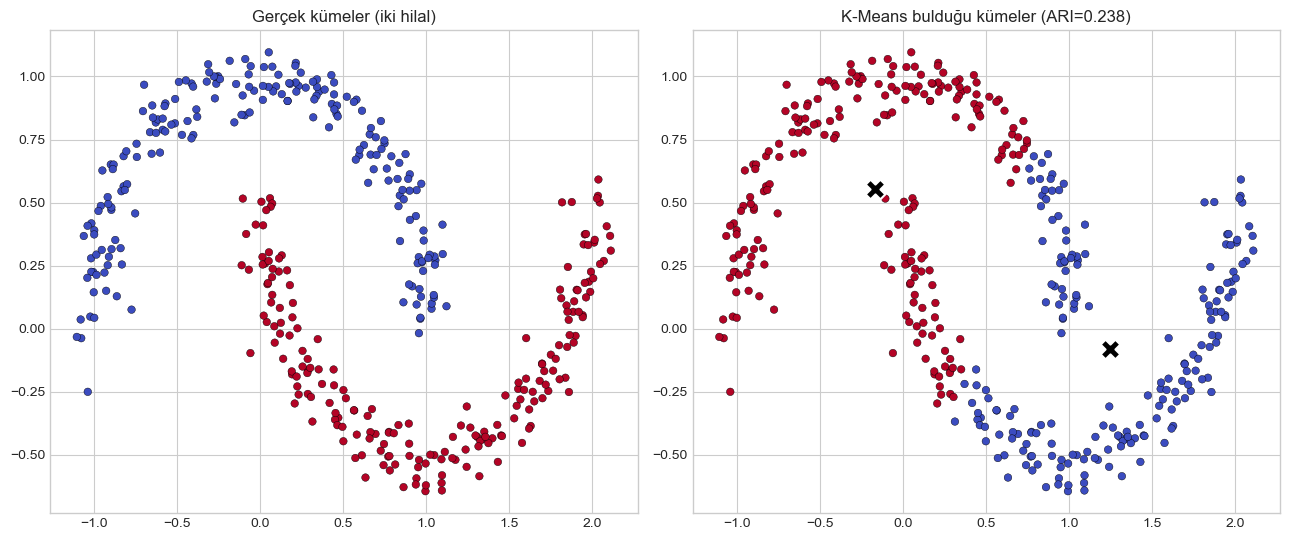


YORUM: K-Means, hilalleri ortadan düz bir çizgiyle ikiye bölüyor — gerçek şekli TAMAMEN kaçırıyor (ARI ~0'a yakın, rastgele atamadan farksız). K-Medoids ve Mini-Batch K-Means de aynı "en yakın merkeze ata" mantığını paylaştığı için bu veride AYNI şekilde başarısız olurdu. 17 · Hiyerarşik ve Yoğunluk Tabanlı Kümeleme'de DBSCAN'ın bu tam veri kümesini doğru şekilde nasıl ayırdığını göreceğiz.


In [92]:
X_moons, y_moons_true = make_moons(n_samples=400, noise=0.07, random_state=42)
km_moons = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons_true, cmap='coolwarm', s=30,
                edgecolor='k', linewidth=0.3)
axes[0].set_title('Gerçek kümeler (iki hilal)')

axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=km_moons.labels_, cmap='coolwarm', s=30,
                edgecolor='k', linewidth=0.3)
axes[1].scatter(km_moons.cluster_centers_[:, 0], km_moons.cluster_centers_[:, 1],
                c='black', marker='X', s=200, edgecolor='white', linewidth=1.5)
axes[1].set_title(f'K-Means bulduğu kümeler (ARI={adjusted_rand_score(y_moons_true, km_moons.labels_):.3f})')
plt.tight_layout(); plt.show()
print('\nYORUM: K-Means, hilalleri ortadan düz bir çizgiyle ikiye bölüyor — gerçek '
      'şekli TAMAMEN kaçırıyor (ARI ~0\'a yakın, rastgele atamadan farksız). K-Medoids ve '
      'Mini-Batch K-Means de aynı "en yakın merkeze ata" mantığını paylaştığı için bu '
      'veride AYNI şekilde başarısız olurdu. 17 · Hiyerarşik ve Yoğunluk Tabanlı '
      'Kümeleme\'de DBSCAN\'ın bu tam veri kümesini doğru şekilde nasıl ayırdığını göreceğiz.')

## Adım 15 · Sentez: Üç Bölümleme Yönteminin Karşılaştırması

**Ne yapıyoruz?** Bu notebook'ta uyguladığımız üç yöntemi, hangi senaryoda hangisinin
tercih edileceğine dair bir karar tablosuyla özetliyoruz.

| Senaryo | Önerilen Yöntem | Bu notebook'taki kanıt |
|---|---|---|
| Orta ölçekli, temiz/aykırı-değersiz veri, hız önemli | **K-Means** | Adım 2-7 (Mall Customer, 200 satır, saniyenin çok altında) |
| Aykırı değerli veya kategorik/özel uzaklık metriği gereken veri, veri küçük-orta ölçekli | **K-Medoids (PAM)** | Adım 9-12 (Wholesale, "hayalet" merkez problemi somut gösterildi) |
| Çok büyük veri (yüz-binler/milyonlar), yaklaşık sonuç kabul edilebilir | **Mini-Batch K-Means** | Adım 13 (1M satır, standart K-Means'e yakın kalite, ~8x hız kazancı — ama çok küçük `batch_size` seçimi tersine tepebilir) |
| Küme şekli küresel/dışbükey DEĞİL (hilal, iç içe halka, çok değişken yoğunluk) | **Hiçbiri — bkz. 17 (DBSCAN/GMM)** | Adım 14 (ay şekli demosu, ARI≈0) |

# 📊 R Uygulaması

R ekosisteminde kümeleme için temel araçlar `stats` paketinde (base R'a dahil,
`kmeans()`) ve `cluster` paketinde (Kaufman & Rousseeuw'un PAM'ı orijinal olarak R'da
yayınladığı paket — `pam()`) bulunuyor. Proje kararı gereği (bkz.
[[notebook_style_convention]]) R bölümünü kısa/sembolik tutuyoruz: 1 hücre `kmeans()` ile
K-Means (Mall verisi), 1 hücre `cluster::pam()` ile K-Medoids (Wholesale verisi) —
Python'daki her adımı ayrı ayrı R'a çevirmiyoruz.

In [93]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [94]:
mall_for_r = mall_df[['Annual_Income_k', 'Spending_Score']]

R kmeans() | k=5 | inertia (tot.withinss) = 65.24057 | iterasyon = 3 


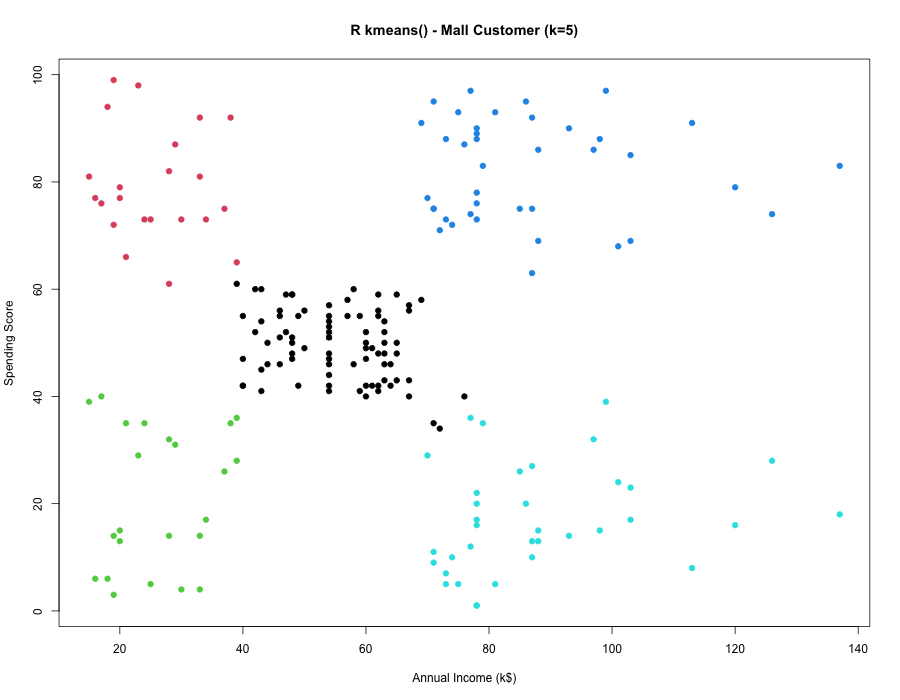

In [95]:
%%R -i mall_for_r -w 900 -h 700
# Çoklu çekirdek yönetimini devre dışı bırakın
options(cores = 1)
options(mc.cores = 1)
if (data.table::getDTthreads() > 1) data.table::setDTthreads(1)

# base R'da kmeans(): Lloyd algoritması, varsayılan olarak Hartigan-Wong yöntemi
mall_scaled_r <- scale(mall_for_r)
set.seed(42)
km_r <- kmeans(mall_scaled_r, centers = 5, nstart = 10)

cat('R kmeans() | k=5 | inertia (tot.withinss) =', km_r$tot.withinss,
    '| iterasyon =', km_r$iter, '\n')

plot(mall_for_r, col = km_r$cluster, pch = 19,
     main = 'R kmeans() - Mall Customer (k=5)',
     xlab = 'Annual Income (k$)', ylab = 'Spending Score')
points(mall_for_r[which.min(rowSums((mall_scaled_r - km_r$centers[km_r$cluster,])^2)), ],
       pch = 4)

In [96]:
wholesale_for_r = wholesale_df[spend_cols]

In [97]:
%%R -i wholesale_for_r
# install.packages("cluster")  # ilk çalıştırmada gerekiyorsa
library(cluster)

# cluster::pam(): Kaufman & Rousseeuw'un ORİJİNAL PAM implementasyonu (bu paket, algoritmanın
# yazarları tarafından yayınlanmıştır) — sklearn_extra'nın Python karşılığı, ama R'da
# `metric` argümanıyla Öklid dışı uzaklıklara (örn. "manhattan") da doğrudan destek verir.
wholesale_scaled_r <- scale(wholesale_for_r)
pam_r <- pam(wholesale_scaled_r, k = 4, metric = "euclidean")

cat('R cluster::pam() | k=4 | ortalama silhouette genişliği =',
    round(pam_r$silinfo$avg.width, 4), '\n')
cat('Medoid satır indeksleri (0-indeksli Python karşılığı için -1):',
    pam_r$id.med - 1, '\n')
print(round(wholesale_for_r[pam_r$id.med, ], 0))

R cluster::pam() | k=4 | ortalama silhouette genişliği = 0.1716 
Medoid satır indeksleri (0-indeksli Python karşılığı için -1): 415 118 374 306 
    Fresh  Milk Grocery Frozen Detergents_Paper Delicassen
415  7842  6046    8552   1691             3540       1874
118 20049  1891    2362   5343              411        933
374  6338  2256    1668   1492              311        686
306  6468 12867   21570   1840             7558       1543


# 🗄️ SQL Uygulaması (DuckDB)

Bu serinin tekrar eden desenini (bkz. [[classical_ml_progress]] "SQL ile Model
Inference'ının Yeniden Üretimi") burada **K-Means'in atama adımına** uyguluyoruz: fit
edilmiş `final_km` modelinin merkezlerini (§Adım 7) bir tabloya, veri noktalarını başka bir
tabloya koyup, "her noktayı en yakın merkeze ata" mantığını saf SQL'de (`CROSS JOIN` +
uzaklık hesabı + `ROW_NUMBER() OVER (PARTITION BY ... ORDER BY uzaklık)`) yeniden
üretiyoruz — sklearn'ün kendi `labels_`'ıyla birebir eşleşmesi bekleniyor. Proje kararı
gereği (bkz. [[notebook_style_convention]]) tek bir örnekle sınırlı tutuyoruz.

In [98]:
import duckdb

con = duckdb.connect()
points_df = pd.DataFrame(X_mall, columns=['income_z', 'spending_z']).assign(
    point_id=range(len(X_mall)))
centers_df = pd.DataFrame(final_km.cluster_centers_, columns=['income_z', 'spending_z']).assign(
    cluster_id=range(final_km.n_clusters))
con.register('points', points_df)
con.register('centers', centers_df)

sql = '''
WITH distances AS (
    SELECT
        p.point_id,
        c.cluster_id,
        POWER(p.income_z - c.income_z, 2) + POWER(p.spending_z - c.spending_z, 2) AS sq_dist
    FROM points p
    CROSS JOIN centers c
),
ranked AS (
    SELECT
        point_id,
        cluster_id,
        ROW_NUMBER() OVER (PARTITION BY point_id ORDER BY sq_dist ASC) AS rnk
    FROM distances
)
SELECT point_id, cluster_id AS sql_label
FROM ranked
WHERE rnk = 1
ORDER BY point_id
'''
sql_labels = con.execute(sql).df()['sql_label'].to_numpy()

n_mismatch = np.sum(sql_labels != final_km.labels_)
print(f'SQL (DuckDB) atama vs sklearn final_km.labels_ | uyuşmayan nokta sayısı: {n_mismatch} / {len(sql_labels)}')
print('\nYORUM: SQL sorgusu, K-Means\'in "en yakın merkeze ata" adımını hiçbir model '
      'kütüphanesi kullanmadan, saf CROSS JOIN + pencere fonksiyonuyla birebir yeniden '
      'üretiyor — bu desen, üretimde bir modelin merkezlerini bir veritabanı tablosunda '
      'tutup yeni gelen kayıtları SQL ile segmentlere atamak (örn. bir BI aracında canlı '
      'sorgu) için doğrudan kullanılabilir.')

SQL (DuckDB) atama vs sklearn final_km.labels_ | uyuşmayan nokta sayısı: 0 / 200

YORUM: SQL sorgusu, K-Means'in "en yakın merkeze ata" adımını hiçbir model kütüphanesi kullanmadan, saf CROSS JOIN + pencere fonksiyonuyla birebir yeniden üretiyor — bu desen, üretimde bir modelin merkezlerini bir veritabanı tablosunda tutup yeni gelen kayıtları SQL ile segmentlere atamak (örn. bir BI aracında canlı sorgu) için doğrudan kullanılabilir.


## ✏️ Egzersizler

**E1.** `SimpleKMeans` sınıfını `n_init` parametresi eklecek şekilde genişlet: verilen
sayıda farklı rastgele başlatmayla fit et ve en düşük inertia'ya sahip sonucu döndür.
Mall verisinde `n_init=1` ile `n_init=10` arasındaki inertia farkını karşılaştır.

In [99]:
import numpy as np

print("\n==== Egzersiz 1: SimpleKMeans için n_init Parametresi ile Inertia Karşılaştırması ====")

class SimpleKMeans:
    def __init__(self, n_clusters=5, init='random', max_iter=300, tol=1e-4,
                 random_state=None, n_init=10):
        self.n_clusters = n_clusters
        self.init = init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.n_init = n_init

    def _get_random_state(self, run_idx):
        # Her n_init adımında tamamen farklı ama tekrar edilebilir (reproducible) 
        # seed'ler üretmek için ana seed ile döngü indeksini harmanlıyoruz.
        if self.random_state is None:
            return np.random.RandomState(None)
        return np.random.RandomState(self.random_state + run_idx)

    def _init_random(self, X, rng):
        idx = rng.choice(len(X), size=self.n_clusters, replace=False)
        return X[idx].copy()

    def _init_kmeanspp(self, X, rng):
        n = len(X)
        centers = np.empty((self.n_clusters, X.shape[1]))
        first_idx = rng.randint(n)
        centers[0] = X[first_idx]
        closest_sq_dist = np.sum((X - centers[0]) ** 2, axis=1)
        for j in range(1, self.n_clusters):
            # Olasılıkların sıfır çıkma ihtimaline karşı küçük bir düzeltme (eps)
            sum_dist = closest_sq_dist.sum()
            probs = closest_sq_dist / (sum_dist if sum_dist > 0 else 1e-6)
            next_idx = rng.choice(n, p=probs)
            centers[j] = X[next_idx]
            new_sq_dist = np.sum((X - centers[j]) ** 2, axis=1)
            closest_sq_dist = np.minimum(closest_sq_dist, new_sq_dist)
        return centers

    def fit(self, X):
        X = np.asarray(X, dtype=float)

        best_inertia = np.inf
        best_centers = None
        best_labels = None
        best_n_iter = 0

        for init_num in range(self.n_init):
            # Her çalışma için bağımsız bir random üretici alıyoruz
            rng = self._get_random_state(init_num)
            
            self.centers_ = (self._init_kmeanspp(X, rng) if self.init == 'k-means++'
                              else self._init_random(X, rng))
            
            for iteration in range(self.max_iter):
                # Atama adımı
                dists = np.linalg.norm(X[:, None, :] - self.centers_[None, :, :], axis=2)
                labels = dists.argmin(axis=1)
                
                # Güncelleme adımı
                new_centers = self.centers_.copy()
                for j in range(self.n_clusters):
                    if np.any(labels == j):
                        new_centers[j] = X[labels == j].mean(axis=0)

                shift = np.linalg.norm(new_centers - self.centers_)
                self.centers_ = new_centers
                if shift < self.tol:
                    break
                    
            current_inertia = float(np.sum((X - self.centers_[labels]) ** 2))

            if current_inertia < best_inertia:
                best_inertia = current_inertia
                best_centers = self.centers_.copy()
                best_labels = labels.copy()
                best_n_iter = iteration + 1

        self.centers_ = best_centers
        self.labels_ = best_labels
        self.inertia_ = best_inertia
        self.n_iter_ = best_n_iter
        
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        dists = np.linalg.norm(X[:, None, :] - self.centers_[None, :, :], axis=2)
        return dists.argmin(axis=1)


# n_init parametresinin etkisini test etme
n_init_values = [1, 5, 10, 20, 50]
inertia_results = []

# Buradaki testi özellikle 'random' başlatma ile yaparsak n_init farkını daha net gözlemleriz
for n_init in n_init_values:
    km = SimpleKMeans(n_clusters=5, init='random', n_init=n_init, random_state=42).fit(X_mall)
    inertia_results.append(km.inertia_)
    print(f'n_init={n_init:2d} | inertia={km.inertia_:.3f} | n_iter={km.n_iter_}')



==== Egzersiz 1: SimpleKMeans için n_init Parametresi ile Inertia Karşılaştırması ====
n_init= 1 | inertia=65.579 | n_iter=11
n_init= 5 | inertia=65.568 | n_iter=8
n_init=10 | inertia=65.568 | n_iter=8
n_init=20 | inertia=65.568 | n_iter=8
n_init=50 | inertia=65.568 | n_iter=8


**E2.** Adım 7'deki 5 segmente **`Age`** özniteliğini de ekleyerek (3 boyutlu K-Means)
kümelemeyi tekrarla. Yeni kümeler, sadece Gelir×Harcama Skoru'na göre bulunan 5 segmentle
aynı mı, yoksa yaş bilgisi segmentasyonu belirgin şekilde değiştiriyor mu?


==== Egzersiz 2: 5 Segmente Yeni Öznitelik Ekleyerek 3 Boyutlu Gösterim ====
SimpleKMeans (k-means++, seed=42) | inertia=168.248 | n_iter=14


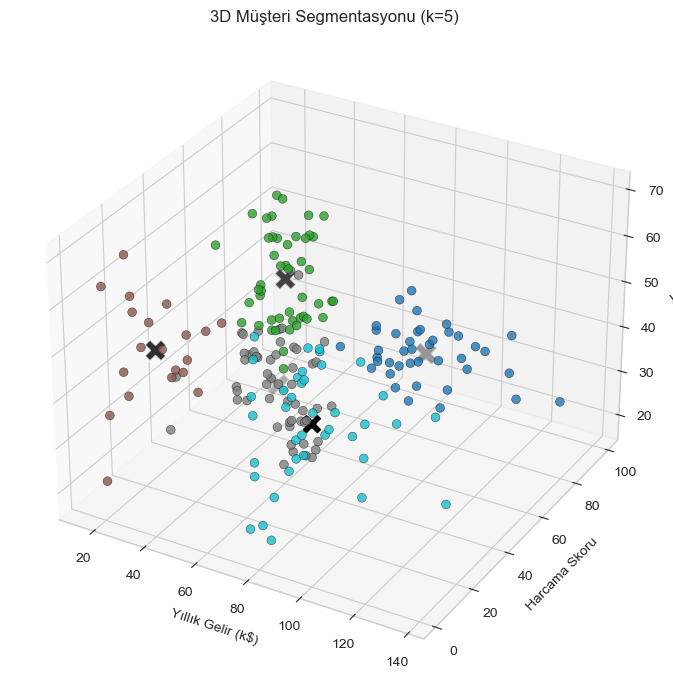

In [100]:
print("\n==== Egzersiz 2: 5 Segmente Yeni Öznitelik Ekleyerek 3 Boyutlu Gösterim ====")

from mpl_toolkits.mplot3d import Axes3D

X_mall_3d = mall_df[['Annual_Income_k', 'Spending_Score', 'Age']].values
scaler_mall = StandardScaler()
X_mall = scaler_mall.fit_transform(X_mall_3d)

my_km_3d = SimpleKMeans(n_clusters=5, init='k-means++', random_state=42).fit(X_mall)
print(f'SimpleKMeans (k-means++, seed=42) | inertia={my_km_3d.inertia_:.3f} | n_iter={my_km_3d.n_iter_}')

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
centers_orig_3d = scaler_mall.inverse_transform(my_km_3d.centers_)
ax.scatter(mall_df['Annual_Income_k'], mall_df['Spending_Score'], mall_df['Age'], c=my_km_3d.labels_, cmap='tab10', s=40, alpha=0.8, edgecolor='k', linewidth=0.3)
ax.scatter(centers_orig_3d[:, 0], centers_orig_3d[:, 1], centers_orig_3d[:, 2], c='black', marker='X', s=250, edgecolor='white', linewidth=1.5)
ax.set_xlabel('Yıllık Gelir (k$)'); ax.set_ylabel('Harcama Skoru'); ax.set_zlabel('Yaş'); ax.set_title('3D Müşteri Segmentasyonu (k=5)')
plt.tight_layout(); plt.show()

**E3.** Wholesale verisinde, Adım 9'daki deneyi **log-dönüşümlü** (`np.log1p`) veriyle
tekrarla. Aykırı-değer-baskın küme sorunu ortadan kalkıyor mu? Küme büyüklüklerini Adım
9'daki ham-veri sonuçlarıyla karşılaştır.

In [101]:
print("\n==== Egzersiz 3: Log Dönüşümlü Veri ile Aykırı Değerlerin Etkisini Gözlemleme ====")

scaler_ws_log = StandardScaler()
X_ws_log = scaler_ws_log.fit_transform(np.log1p(wholesale_df[spend_cols]))

km_log = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X_ws_log)
cluster_sizes_log = pd.Series(km_log.labels_).value_counts().sort_index()
print('Log dönüşümlü veride küme büyüklükleri:')
print(cluster_sizes_log)

outlier_cluster_log = cluster_sizes_log.idxmin()
print('\nBu kümedeki müşterilerin log(1+x) harcamaları (parasal birim):')
print(np.expm1(wholesale_df.loc[km_log.labels_ == outlier_cluster_log, spend_cols].apply(np.log1p).describe().round(2).loc[['mean', 'max']]))


==== Egzersiz 3: Log Dönüşümlü Veri ile Aykırı Değerlerin Etkisini Gözlemleme ====
Log dönüşümlü veride küme büyüklükleri:
0     61
1    129
2    132
3    118
Name: count, dtype: int64

Bu kümedeki müşterilerin log(1+x) harcamaları (parasal birim):
             Fresh          Milk       Grocery       Frozen  Detergents_Paper  \
mean    905.870807   5942.182243  10096.064328   300.871068       3427.917868   
max   25590.102207  20951.222382  45705.692026  6246.895712      24342.009424   

       Delicassen  
mean   246.151127  
max   6373.111578  


**E4.** `SimplePAM`'ı `Channel` (Horeca vs Perakende) etiketiyle karşılaştır: PAM'ın 2
kümeyle (k=2) bulduğu ayrım, gerçek `Channel` etiketiyle ne kadar örtüşüyor
(`sklearn.metrics.adjusted_rand_score` kullan)?


==== Egzersiz 4: Channel Etiketiyle Kümeleme Sonuçlarını Karşılaştırma ====


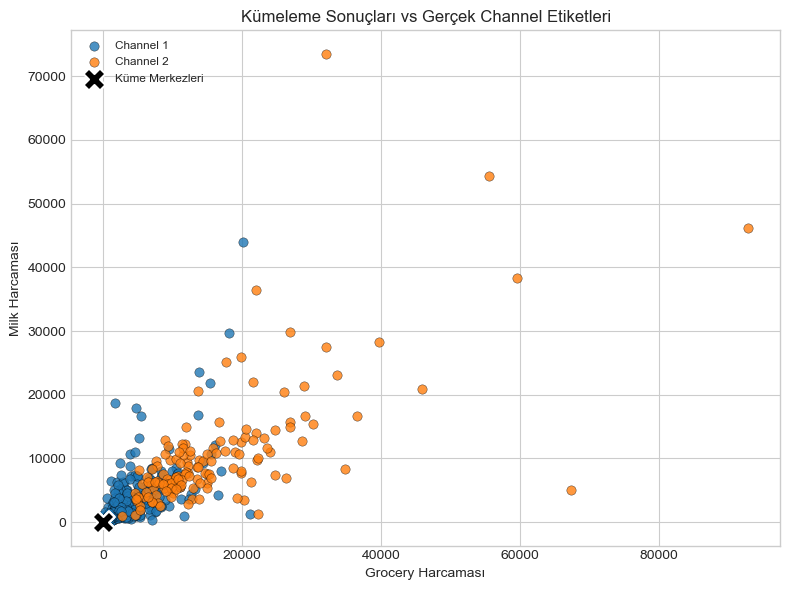

Gerçek Channel etiketleri ile ölçüşüyor mu 0.2799? 0.0 = rastgele, 1.0 = mükemmel uyum. 


In [102]:
print("\n==== Egzersiz 4: Channel Etiketiyle Kümeleme Sonuçlarını Karşılaştırma ====")

df_channel = wholesale_df.copy()
df_channel['Channel'] = df_channel['Channel'].astype('category')
df_horeca_perakende = df_channel[df_channel['Channel'].isin([1, 2])].copy()
X_ws_channel = scaler_ws_log.fit_transform(np.log1p(df_horeca_perakende[spend_cols]))
km_channel = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X_ws_channel)
rand_index = adjusted_rand_score(df_channel['Channel'], km_channel.labels_)

plt.figure(figsize=(8, 6))
for channel in sorted(df_horeca_perakende['Channel'].unique()):
    sub = df_horeca_perakende[df_horeca_perakende['Channel'] == channel]
    plt.scatter(sub['Grocery'], sub['Milk'], s=45, alpha=0.8,
                edgecolor='k', linewidth=0.3, label=f'Channel {channel}')
centers_orig_channel = scaler_ws_log.inverse_transform(km_channel.cluster_centers_)
plt.scatter(centers_orig_channel[:, 2], centers_orig_channel[:, 1], c='black', marker='X', s=250,
            edgecolor='white', linewidth=1.5, label='Küme Merkezleri')
plt.xlabel('Grocery Harcaması'); plt.ylabel('Milk Harcaması')
plt.title('Kümeleme Sonuçları vs Gerçek Channel Etiketleri')
plt.legend(loc='upper left', fontsize=8.5); plt.tight_layout(); plt.show()

print(f"Gerçek Channel etiketleri ile ölçüşüyor mu {rand_index:.4f}? 0.0 = rastgele, 1.0 = mükemmel uyum. ")

**E5.** Adım 13'teki büyük sentetik veride, `MiniBatchKMeans`'in `reassignment_ratio`
parametresini varsayılandan (0.01) çok daha yüksek bir değere (örn. 0.5) çıkararak fit et.
Süre ve inertia nasıl değişiyor? Dokümantasyondaki tanımına bakarak neden bu şekilde
değiştiğini açıkla.

In [103]:
print("\n==== Egzersiz 5: Ressaigment Ratio Parametresi ile Inertia Karşılaştırması ====")

reassing_ratios = [0.0, 0.05, 0.1, 0.2, 0.5]

for ratio in reassing_ratios:
    km_reassign = MiniBatchKMeans(n_clusters=8, init='k-means++', n_init=5,batch_size = 1024 ,random_state=42, reassignment_ratio=ratio).fit(X_ws_log)
    print(f"Reassignment Ratio={ratio:.2f} | Inertia={km_reassign.inertia_:.3f} | n_iter={km_reassign.n_iter_}")


==== Egzersiz 5: Ressaigment Ratio Parametresi ile Inertia Karşılaştırması ====
Reassignment Ratio=0.00 | Inertia=1066.461 | n_iter=38
Reassignment Ratio=0.05 | Inertia=1066.461 | n_iter=38
Reassignment Ratio=0.10 | Inertia=1066.461 | n_iter=38
Reassignment Ratio=0.20 | Inertia=1138.973 | n_iter=17
Reassignment Ratio=0.50 | Inertia=1149.637 | n_iter=52


### Yorum 5:
Reassignment Ratio parametresi, Mini-Batch K-Means algoritmasında düşük veri yoğunluğuna sahip veya atıl kalan küme merkezlerinin, verilerin daha yoğun olduğu bölgelere ne sıklıkla yeniden atanacağını kontrol eder. Teorik olarak bu parametrenin artırılması yerel minimumlardan kaçmaya yardımcı olsa da, elde ettiğimiz sonuçlar bu veri setinde yüksek oranların (0.20 ve 0.50) algoritmanın kararlılığını bozduğunu göstermektedir.
Düşük oranlarda (0.00 - 0.10) en optimum kümeleme kalitesi (en düşük Inertia: 1066.461) elde edilmişken; oran 0.50'ye çıkarıldığında hem hata payı artmış hem de algoritmanın yakınsama süresi (52 iterasyon) uzamıştır. Sonuç olarak, bu senaryo için düşük bir Reassignment Ratio (örneğin 0.05 veya 0.00) seçmek hem hız hem de kalite açısından en uygun dengedir.

**E6.** Adım 14'teki ay-şekli verisine, K-Means'i **k=4** ile (gerçek küme sayısı yerine
fazla sayıda küme vererek) uygula ve görselleştir. K-Means'in "yanlış" bir k ile bile
mantıklı görünen ama gerçekte anlamsız kümeler üretebileceğini gözlemle — bu neden $k$
seçiminde sadece görsel/sayısal metriklere değil, alan bilgisine de ihtiyaç duyduğumuzu
gösterir?


==== Egzersiz 5: Ay Şeklindeki Modelleme Verisine Daha Fazla Küme Sayısı ile Uygulama ====


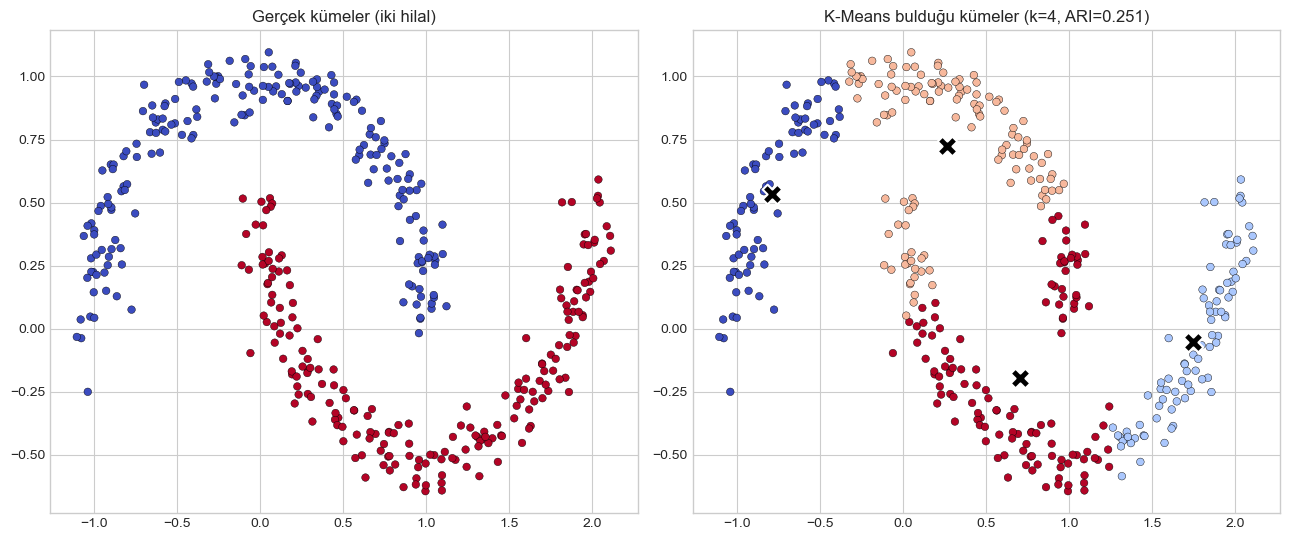

In [104]:
print("\n==== Egzersiz 5: Ay Şeklindeki Modelleme Verisine Daha Fazla Küme Sayısı ile Uygulama ====")

X_moons_more_clusters, y_moons_true_more_clusters = make_moons(n_samples=400, noise=0.07, random_state=42)
km_moons_more_clusters = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X_moons_more_clusters)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(X_moons_more_clusters[:, 0], X_moons_more_clusters[:, 1], c=y_moons_true_more_clusters, cmap='coolwarm', s=30,
                edgecolor='k', linewidth=0.3)
axes[0].set_title('Gerçek kümeler (iki hilal)')

axes[1].scatter(X_moons_more_clusters[:, 0], X_moons_more_clusters[:, 1], c=km_moons_more_clusters.labels_, cmap='coolwarm', s=30,
                edgecolor='k', linewidth=0.3)
axes[1].scatter(km_moons_more_clusters.cluster_centers_[:, 0], km_moons_more_clusters.cluster_centers_[:, 1],
                c='black', marker='X', s=200, edgecolor='white', linewidth=1.5)
axes[1].set_title(f'K-Means bulduğu kümeler (k=4, ARI={adjusted_rand_score(y_moons_true_more_clusters, km_moons_more_clusters.labels_):.3f})')
plt.tight_layout(); plt.show()

## 📚 Kaynaklar

| Kaynak | Bölüm | Notlar |
|---|---|---|
| [MacQueen (1967) — "Some Methods for Classification and Analysis of Multivariate Observations"](https://digitalassets.lib.berkeley.edu/math/ucb/text/math_s5_v1_article-17.pdf) | K-Means'in orijini | "K-means" adının ilk kullanıldığı makale (Berkeley Symposium) |
| [Arthur & Vassilvitskii (2007) — "k-means++: The Advantages of Careful Seeding"](https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf) | k-means++ başlatma | Stanford — yaklaşım garantisinin ($O(\log k)$) orijinal kanıtı |
| [Kaufman & Rousseeuw (1990) — *Finding Groups in Data: An Introduction to Cluster Analysis*](https://onlinelibrary.wiley.com/doi/book/10.1002/9780470316801) | PAM (K-Medoids) | PAM algoritmasının orijinal kitabı; `cluster` R paketinin (`pam()`) doğrudan referansı |
| [Rousseeuw (1987) — "Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis"](https://www.sciencedirect.com/science/article/pii/0377042787901257) | Silhouette Score | Silhouette katsayısının orijinal makalesi (J. Computational and Applied Mathematics) |
| [Sculley (2010) — "Web-Scale K-Means Clustering"](https://www.eecs.tufts.edu/~dsculley/papers/fastkmeans.pdf) | Mini-Batch K-Means | Google — orijinal makale, WWW 2010 |
| [scikit-learn — Clustering (User Guide)](https://scikit-learn.org/stable/modules/clustering.html) | K-Means, Mini-Batch K-Means, metrikler | Resmi dokümantasyon — API detayları ve algoritma karşılaştırma tablosu |
| [scikit-learn-extra — KMedoids](https://scikit-learn-extra.readthedocs.io/en/stable/generated/sklearn_extra.cluster.KMedoids.html) | K-Medoids (Python) | `method='pam'`/`'alternate'` API dokümantasyonu |
| [Mall Customer Segmentation Data (Kaggle, vjchoudhary7)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) | Adım 1-7 veri seti | Orijinal Kaggle veri seti sayfası |
| [Wholesale customers (UCI Machine Learning Repository)](https://archive.ics.uci.edu/dataset/292/wholesale+customers) | Adım 8-12 veri seti | Cardoso, M. G. M. S. (2014) — orijinal UCI sayfası ve değişken tanımları |
| [DuckDB — SQL üzerine Python entegrasyonu](https://duckdb.org/docs/api/python/overview) | SQL Uygulaması | Resmi dokümantasyon |